In [1]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy import signal
from scipy.ndimage import gaussian_filter1d
from scipy.signal import stft
from tqdm.auto import tqdm

# ============================================================
# Global configuration
# ============================================================

FS = 256_000
N_SAMPLES = 4096

NFFT = 256
HOP = 64
NO_OVERLAP = NFFT - HOP

DIGITAL_SYMBOL_RATE=16_000
DIGITAL_SPS=FS//DIGITAL_SYMBOL_RATE

SNR_MIN_DB = 5.0
SNR_MAX_DB = 20.0

NUM_CLASSES = 11
MAX_EMITTERS = 3

RANDOM_SEED = 42

SPLIT_SIZES = {
    "train": 1000,
    "val": 200,
    "test": 300
}

OUTPUT_DIR = "rf_mvp_dataset"
os.makedirs(OUTPUT_DIR, exist_ok=True)

CLASS_NAMES = [
    "CW", "AM", "NBFM",
    "BPSK", "QPSK", "8PSK",
    "16QAM", "64QAM",
    "2FSK", "4FSK", "GMSK"
]

CLASS_TO_ID = {
    name: idx for idx, name in enumerate(CLASS_NAMES)
}

TIME_AXIS = np.arange(N_SAMPLES) / FS

# ============================================================
# STFT configuration
# ============================================================

FREQ_AXIS = np.fft.fftshift(
    np.fft.fftfreq(NFFT, d=1 / FS)
)

FRAME_TIMES = np.arange(
    0, N_SAMPLES + 1, HOP
) / FS

NUM_FRAMES = len(FRAME_TIMES)

# ============================================================
# Configuration validation
# ============================================================

assert NFFT > 0
assert HOP > 0
assert HOP <= NFFT
assert N_SAMPLES % HOP == 0
assert SNR_MIN_DB <= SNR_MAX_DB
assert NUM_CLASSES == len(CLASS_NAMES)
assert len(CLASS_TO_ID) == NUM_CLASSES
assert len(set(CLASS_NAMES)) == NUM_CLASSES
assert FS%DIGITAL_SYMBOL_RATE==0
assert DIGITAL_SPS==16
assert NFFT==256
assert HOP==64

# ============================================================
# Configuration summary
# ============================================================

print("=" * 55)
print("RF DATASET CONFIGURATION")
print("=" * 55)

print("Sampling rate:", FS)
print("Signal duration:", N_SAMPLES / FS * 1000, "ms")
print("FFT size:", NFFT)
print("Overlap:", NO_OVERLAP)
print("Frequency bins:", len(FREQ_AXIS))
print("Time frames:", NUM_FRAMES)
print("Frequency resolution:", FS / NFFT, "Hz")
print("Time hop:", HOP / FS * 1000, "ms")
print("Number of classes:", NUM_CLASSES)
print("Maximum emitters:", MAX_EMITTERS)
print("SNR range:", SNR_MIN_DB, "to", SNR_MAX_DB, "dB")

print("\nClass mapping:")
for name, idx in CLASS_TO_ID.items():
    print(f"{idx}: {name}")

print("\nConfiguration validation: PASSED")


RF DATASET CONFIGURATION
Sampling rate: 256000
Signal duration: 16.0 ms
FFT size: 256
Overlap: 192
Frequency bins: 256
Time frames: 65
Frequency resolution: 1000.0 Hz
Time hop: 0.25 ms
Number of classes: 11
Maximum emitters: 3
SNR range: 5.0 to 20.0 dB

Class mapping:
0: CW
1: AM
2: NBFM
3: BPSK
4: QPSK
5: 8PSK
6: 16QAM
7: 64QAM
8: 2FSK
9: 4FSK
10: GMSK

Configuration validation: PASSED


/Users/tohid/Desktop/RF-Signal-Detection/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:

# ============================================================
# Utility functions
# ============================================================

def normalize_power(x):
    """Normalize a complex waveform to unit average power."""

    x = np.asarray(x, dtype=np.complex128)

    if not np.all(np.isfinite(x)):
        raise ValueError("Waveform contains NaN or Inf.")

    power = np.mean(np.abs(x) ** 2)

    if power < 1e-12:
        raise ValueError("Cannot normalize a zero-power waveform.")

    return (x / np.sqrt(power)).astype(np.complex64)


def rrc_filter(beta=0.35, span=8, sps=DIGITAL_SPS):
    """Generate a normalized Root Raised Cosine filter."""

    if not 0 <= beta <= 1:
        raise ValueError("beta must be between 0 and 1.")

    if span <= 0 or sps <= 0:
        raise ValueError("span and sps must be positive.")

    t = np.arange(
        -span * sps // 2,
        span * sps // 2 + 1
    ) / sps

    h = np.zeros_like(t, dtype=np.float64)

    for i, ti in enumerate(t):

        if abs(ti) < 1e-10:
            h[i] = 1 + beta * (4 / np.pi - 1)

        elif beta > 0 and abs(abs(4 * beta * ti) - 1) < 1e-8:
            h[i] = (
                beta / np.sqrt(2)
                * (
                    (1 + 2 / np.pi)
                    * np.sin(np.pi / (4 * beta))
                    +
                    (1 - 2 / np.pi)
                    * np.cos(np.pi / (4 * beta))
                )
            )

        else:
            numerator = (
                np.sin(np.pi * ti * (1 - beta))
                +
                4 * beta * ti
                * np.cos(np.pi * ti * (1 + beta))
            )

            denominator = (
                np.pi * ti
                * (1 - (4 * beta * ti) ** 2)
            )

            h[i] = numerator / denominator

    h /= np.sqrt(np.sum(h ** 2))

    return h


def shaped_symbols(
    symbols,
    sps=DIGITAL_SPS,
    beta=0.35
):
    """Upsample and pulse-shape digital modulation symbols."""

    filt = rrc_filter(
        beta=beta,
        span=8,
        sps=sps
    )

    upsampled = np.zeros(
        len(symbols) * sps,
        dtype=np.complex128
    )

    upsampled[::sps] = symbols

    return signal.fftconvolve(
        upsampled,
        filt,
        mode="same"
    )


def random_qam(order, rng, size):
    """Generate square QAM symbols with fixed theoretical normalization."""

    side = int(np.sqrt(order))

    if side * side != order:
        raise ValueError("Only square QAM orders are supported.")

    levels = np.arange(-(side - 1), side, 2)

    i_values = rng.choice(levels, size=size)
    q_values = rng.choice(levels, size=size)

    symbols = i_values + 1j * q_values

    theoretical_power = 2 * (order - 1) / 3

    return symbols / np.sqrt(theoretical_power)


# ============================================================
# Digital modulation generators
# ============================================================

def generate_digital_modulation(
    modulation,
    n_samples,
    rng,
    sps=DIGITAL_SPS,
    rrc_beta=0.35
):
    """Generate PSK and QAM complex baseband signals."""

    guard_symbols = 10

    n_symbols = (
        int(np.ceil(n_samples / sps))
        + 2 * guard_symbols
    )

    if modulation == "BPSK":

        symbols = rng.choice(
            [-1, 1],
            size=n_symbols
        ).astype(np.complex128)

    elif modulation == "QPSK":

        indices = rng.integers(
            0, 4,
            size=n_symbols
        )

        symbols = np.exp(
            1j * (np.pi / 4 + indices * np.pi / 2)
        )

    elif modulation == "8PSK":

        indices = rng.integers(
            0, 8,
            size=n_symbols
        )

        symbols = np.exp(
            1j * 2 * np.pi * indices / 8
        )

    elif modulation == "16QAM":

        symbols = random_qam(
            16, rng, n_symbols
        )

    elif modulation == "64QAM":

        symbols = random_qam(
            64, rng, n_symbols
        )

    else:
        raise ValueError(
            f"Unsupported digital modulation: {modulation}"
        )

    waveform = shaped_symbols(
        symbols,
        sps=sps,
        beta=rrc_beta
    )

    start = guard_symbols * sps

    waveform = waveform[
        start:start + n_samples
    ]

    if len(waveform) != n_samples:
        raise RuntimeError("Invalid digital waveform length.")

    return normalize_power(waveform)


# ============================================================
# FSK generator
# ============================================================

def generate_fsk(
    modulation,
    n_samples,
    rng,
    symbol_rate=DIGITAL_SYMBOL_RATE,
    modulation_index=0.5
):
    """Generate continuous-phase M-ary FSK signals."""

    if symbol_rate <= 0 or FS % symbol_rate != 0:
        raise ValueError("Invalid FSK symbol rate.")

    if modulation_index <= 0:
        raise ValueError("Modulation index must be positive.")

    sps = FS // symbol_rate

    n_symbols = (
        int(np.ceil(n_samples / sps)) + 1
    )

    if modulation == "2FSK":
        levels = np.array([-1, 1])

    elif modulation == "4FSK":
        levels = np.array([-3, -1, 1, 3])

    else:
        raise ValueError("Unsupported FSK modulation.")

    symbols = rng.choice(
        levels,
        size=n_symbols
    )

    frequency_deviation = (
        modulation_index * symbol_rate / 2
    )

    frequency = np.repeat(
        symbols * frequency_deviation,
        sps
    )[:n_samples]

    phase = (
        2 * np.pi
        * np.concatenate((
            [0.0],
            np.cumsum(frequency[:-1])
        ))
        / FS
    )

    waveform = np.exp(1j * phase)

    return normalize_power(waveform)


# ============================================================
# Gaussian filter for GMSK
# ============================================================

def gaussian_filter_taps(
    bt=0.3,
    sps=DIGITAL_SPS,
    span=8
):
    """Generate a normalized Gaussian pulse-shaping filter."""

    if bt <= 0:
        raise ValueError("BT must be positive.")

    t = np.arange(
        -span * sps // 2,
        span * sps // 2 + 1
    ) / sps

    h = (
        np.sqrt(2 * np.pi / np.log(2))
        * bt
        * np.exp(
            -2 * np.pi ** 2
            * bt ** 2
            * t ** 2
            / np.log(2)
        )
    )

    h /= np.sum(h)

    return h


# ============================================================
# GMSK generator
# ============================================================

def generate_gmsk(
    n_samples,
    rng,
    symbol_rate=DIGITAL_SYMBOL_RATE,
    bt=0.3,
    modulation_index=0.5
):
    """Generate Gaussian-filtered CPFSK with GMSK parameters."""

    if symbol_rate <= 0 or FS % symbol_rate != 0:
        raise ValueError("Invalid GMSK symbol rate.")

    if bt <= 0 or modulation_index <= 0:
        raise ValueError("Invalid GMSK parameters.")

    sps = FS // symbol_rate

    guard_symbols = 12

    n_symbols = (
        int(np.ceil(n_samples / sps))
        + 2 * guard_symbols
    )

    bits = rng.choice(
        [-1.0, 1.0],
        size=n_symbols
    )

    nrz = np.repeat(bits, sps)

    gaussian_taps = gaussian_filter_taps(
        bt=bt,
        sps=sps,
        span=8
    )

    shaped = signal.fftconvolve(
        nrz,
        gaussian_taps,
        mode="same"
    )

    instantaneous_frequency = (
        modulation_index
        * symbol_rate
        * shaped
        / 2
    )

    phase = (
        2 * np.pi
        * np.concatenate((
            [0.0],
            np.cumsum(instantaneous_frequency[:-1])
        ))
        / FS
    )

    waveform = np.exp(1j * phase)

    start = guard_symbols * sps

    waveform = waveform[
        start:start + n_samples
    ]

    if len(waveform) != n_samples:
        raise RuntimeError("Invalid GMSK waveform length.")

    return normalize_power(waveform)


# ============================================================
# Analog modulation generators
# ============================================================

def generate_analog_modulation(
    modulation,
    n_samples,
    rng,
    am_modulation_index=0.7,
    nbfm_deviation_hz=2000
):
    """Generate CW, AM and NBFM complex baseband signals."""

    t = np.arange(n_samples) / FS

    message_freq = rng.uniform(500, 4000)

    message = (
        0.7 * np.sin(
            2 * np.pi * message_freq * t
        )
        +
        0.2 * np.sin(
            2 * np.pi * 1.7 * message_freq * t
        )
    )

    message /= np.max(np.abs(message))

    if modulation == "CW":

        waveform = np.ones(
            n_samples,
            dtype=np.complex128
        )

    elif modulation == "AM":

        if not 0 <= am_modulation_index <= 1:
            raise ValueError("Invalid AM modulation index.")

        envelope = (
            1 + am_modulation_index * message
        )

        waveform = envelope.astype(np.complex128)

    elif modulation == "NBFM":

        if nbfm_deviation_hz <= 0:
            raise ValueError("Invalid NBFM deviation.")

        phase = (
            2 * np.pi
            * nbfm_deviation_hz
            * np.concatenate((
                [0.0],
                np.cumsum(message[:-1])
            ))
            / FS
        )

        waveform = np.exp(1j * phase)

    else:
        raise ValueError(
            f"Unsupported analog modulation: {modulation}"
        )

    return normalize_power(waveform)


# ============================================================
# Main modulation dispatcher
# ============================================================

def generate_modulated_signal(
    modulation,
    n_samples,
    rng
):
    """Generate one normalized complex baseband signal."""

    if modulation in ["CW", "AM", "NBFM"]:

        return generate_analog_modulation(
            modulation,
            n_samples,
            rng
        )

    if modulation in [
        "BPSK", "QPSK", "8PSK",
        "16QAM", "64QAM"
    ]:

        return generate_digital_modulation(
            modulation,
            n_samples,
            rng
        )

    if modulation in ["2FSK", "4FSK"]:

        return generate_fsk(
            modulation,
            n_samples,
            rng
        )

    if modulation == "GMSK":

        return generate_gmsk(
            n_samples,
            rng
        )

    raise ValueError(
        f"Unknown modulation: {modulation}"
    )


INTEGRATED SIGNAL GENERATOR VALIDATION

Validating: CW
  Power: 1.000000 | Bandwidth: 0.50 kHz | PSD: VALID

Validating: AM
  Power: 1.000000 | Bandwidth: 9.00 kHz | PSD: VALID

Validating: NBFM
  Power: 1.000000 | Bandwidth: 7.50 kHz | PSD: VALID

Validating: BPSK
  Power: 1.000000 | Bandwidth: 18.50 kHz | PSD: VALID

Validating: QPSK
  Power: 1.000000 | Bandwidth: 18.50 kHz | PSD: VALID

Validating: 8PSK
  Power: 1.000000 | Bandwidth: 18.50 kHz | PSD: VALID

Validating: 16QAM
  Power: 1.000000 | Bandwidth: 19.00 kHz | PSD: VALID

Validating: 64QAM
  Power: 1.000000 | Bandwidth: 18.75 kHz | PSD: VALID

Validating: 2FSK
  Power: 1.000000 | Bandwidth: 19.25 kHz | PSD: VALID

Validating: 4FSK
  Power: 1.000000 | Bandwidth: 41.00 kHz | PSD: VALID

Validating: GMSK
  Power: 1.000000 | Bandwidth: 14.50 kHz | PSD: VALID


VALIDATION RESULTS


,class,length,dtype,avg_power,peak_amplitude,bandwidth_99_khz,occupied_lower_khz,occupied_upper_khz,inst_freq_p01_khz,inst_freq_p99_khz,finite,valid_length,valid_power,psd_valid
0,CW,4096,complex64,1.0,1.0000,0.50,-0.25,0.25,NaN,NaN,True,True,True,True
1,AM,4096,complex64,1.0,1.5758,9.00,-4.50,4.50,NaN,NaN,True,True,True,True
2,NBFM,4096,complex64,1.0,1.0000,7.50,-3.75,3.75,-1.9521,1.9405,True,True,True,True
3,BPSK,4096,complex64,1.0,1.5534,18.50,-9.25,9.25,NaN,NaN,True,True,True,True
4,QPSK,4096,complex64,1.0,1.4670,18.50,-9.25,9.25,NaN,NaN,True,True,True,True
5,8PSK,4096,complex64,1.0,1.4838,18.50,-9.25,9.25,NaN,NaN,True,True,True,True
6,16QAM,4096,complex64,1.0,1.8550,19.00,-9.50,9.50,NaN,NaN,True,True,True,True
7,64QAM,4096,complex64,1.0,2.0418,18.75,-9.25,9.50,NaN,NaN,True,True,True,True
8,2FSK,4096,complex64,1.0,1.0000,19.25,-9.75,9.50,-4.0000,4.0000,True,True,True,True
9,4FSK,4096,complex64,1.0,1.0000,41.00,-20.25,20.75,-12.0000,12.0000,True,True,True,True




STRUCTURAL VALIDATION SUMMARY
Total classes: 11
Successful PSD calculations: 11
Structural validation: PASSED


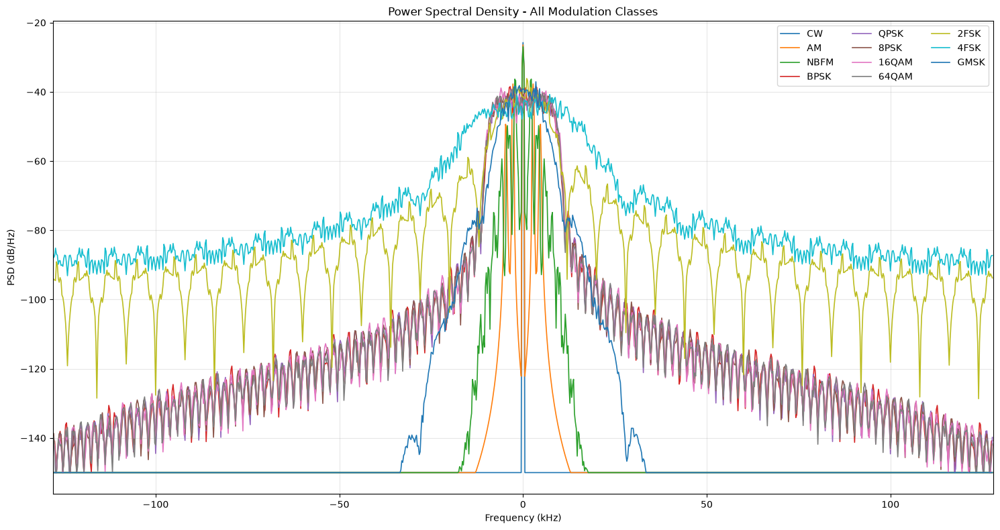

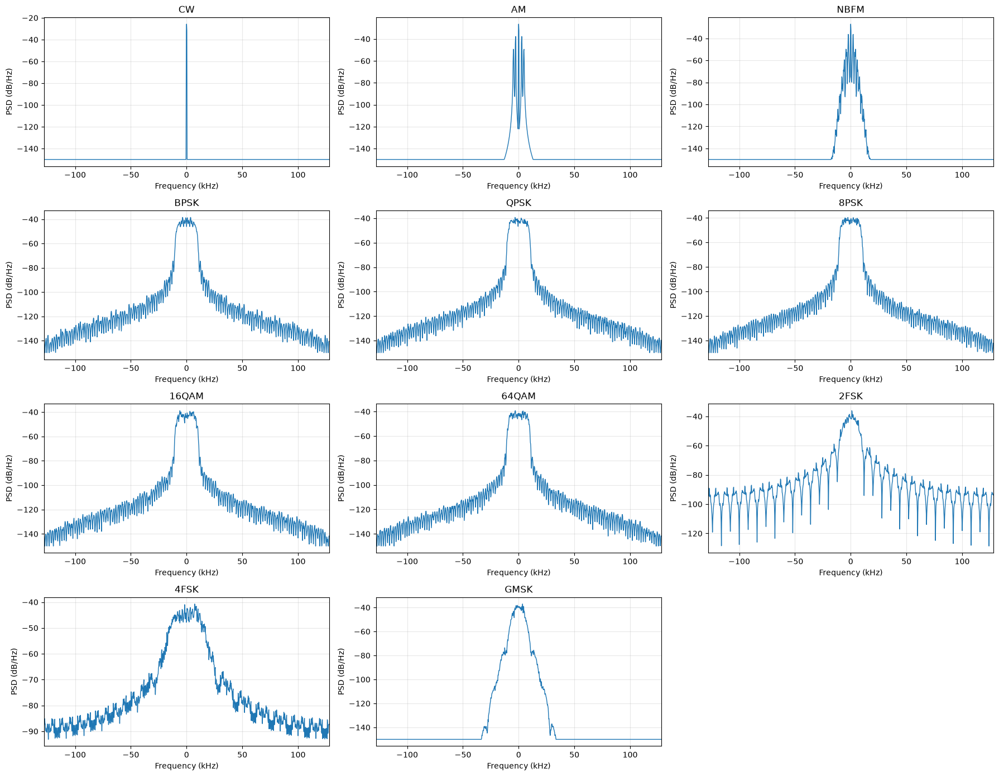



FINAL ERROR REPORT
No execution errors detected.

Validation cell completed.


In [3]:
# testbench:



# ============================================================
# INTEGRATED SIGNAL GENERATOR VALIDATION
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy import signal


# ============================================================
# Configuration
# ============================================================

VALIDATION_SEED = 2026

PSD_NPERSEG = 1024
PSD_NOVERLAP = 512

OCCUPIED_BANDWIDTH_PERCENT = 99.0

VALIDATION_CLASSES = CLASS_NAMES.copy()

FREQUENCY_MODULATED_CLASSES = [
    "NBFM",
    "2FSK",
    "4FSK",
    "GMSK"
]

rng = np.random.default_rng(VALIDATION_SEED)


# ============================================================
# PSD Calculation
# ============================================================

def calculate_psd(waveform):
    """Calculate two-sided complex-baseband PSD."""

    freqs, psd = signal.welch(
        waveform,
        fs=FS,
        window="hann",
        nperseg=PSD_NPERSEG,
        noverlap=PSD_NOVERLAP,
        return_onesided=False,
        scaling="density",
        detrend=False
    )

    freqs = np.fft.fftshift(freqs)
    psd = np.fft.fftshift(psd)

    total_power = np.sum(psd)

    if (
        total_power <= 0
        or not np.isfinite(total_power)
        or not np.all(np.isfinite(psd))
    ):
        raise ValueError("Invalid PSD power.")

    cumulative_power = np.cumsum(psd) / total_power

    return freqs, psd, cumulative_power


# ============================================================
# Occupied Bandwidth Calculation
# ============================================================

def calculate_occupied_bandwidth(
    freqs,
    cumulative_power,
    percentage=99.0
):
    """Calculate the central occupied bandwidth."""

    lower_fraction = (100.0 - percentage) / 200.0
    upper_fraction = 1.0 - lower_fraction

    lower_index = np.searchsorted(
        cumulative_power,
        lower_fraction
    )

    upper_index = np.searchsorted(
        cumulative_power,
        upper_fraction
    )

    lower_index = min(lower_index, len(freqs) - 1)
    upper_index = min(upper_index, len(freqs) - 1)

    lower_freq = freqs[lower_index]
    upper_freq = freqs[upper_index]

    bandwidth = upper_freq - lower_freq

    return (
        bandwidth,
        lower_freq,
        upper_freq
    )


# ============================================================
# Instantaneous Frequency Calculation
# ============================================================

def calculate_instantaneous_frequency(waveform):
    """Calculate instantaneous frequency for continuous-phase signals."""

    phase = np.unwrap(np.angle(waveform))

    instantaneous_frequency = (
        np.diff(phase) * FS / (2 * np.pi)
    )

    instantaneous_frequency = instantaneous_frequency[
        np.isfinite(instantaneous_frequency)
    ]

    if len(instantaneous_frequency) == 0:
        raise ValueError("Invalid instantaneous frequency.")

    return (
        np.percentile(instantaneous_frequency, 1) / 1000,
        np.percentile(instantaneous_frequency, 99) / 1000
    )


# ============================================================
# Signal Validation
# ============================================================

def validate_waveform(waveform):
    """Validate waveform structure and numerical properties."""

    waveform = np.asarray(waveform)

    finite = bool(
        np.all(np.isfinite(waveform))
    )

    valid_length = (
        len(waveform) == N_SAMPLES
    )

    avg_power = float(
        np.mean(np.abs(waveform) ** 2)
    )

    peak_amplitude = float(
        np.max(np.abs(waveform))
    )

    valid_power = (
        np.isfinite(avg_power)
        and abs(avg_power - 1.0) < 1e-4
    )

    return {
        "length": len(waveform),
        "dtype": str(waveform.dtype),
        "avg_power": avg_power,
        "peak_amplitude": peak_amplitude,
        "finite": finite,
        "valid_length": valid_length,
        "valid_power": valid_power
    }


# ============================================================
# Main Validation Loop
# ============================================================

results = []
psd_results = {}
waveform_results = {}

print("=" * 100)
print("INTEGRATED SIGNAL GENERATOR VALIDATION")
print("=" * 100)

for class_name in VALIDATION_CLASSES:

    print(f"\nValidating: {class_name}")

    try:

        # Generate waveform
        waveform = generate_modulated_signal(
            class_name,
            N_SAMPLES,
            rng
        )

        waveform_results[class_name] = waveform

        # Structural validation
        validation = validate_waveform(waveform)

        # PSD validation
        freqs, psd, cumulative_power = calculate_psd(
            waveform
        )

        bandwidth, lower_freq, upper_freq = (
            calculate_occupied_bandwidth(
                freqs,
                cumulative_power,
                OCCUPIED_BANDWIDTH_PERCENT
            )
        )

        psd_results[class_name] = {
            "freqs": freqs,
            "psd": psd
        }

        # Instantaneous frequency:
        # Only meaningful for the selected continuous-phase classes.
        inst_freq_p01 = np.nan
        inst_freq_p99 = np.nan

        if class_name in FREQUENCY_MODULATED_CLASSES:

            inst_freq_p01, inst_freq_p99 = (
                calculate_instantaneous_frequency(
                    waveform
                )
            )

        result = {
            "class": class_name,
            **validation,
            "bandwidth_99_khz": bandwidth / 1000,
            "occupied_lower_khz": lower_freq / 1000,
            "occupied_upper_khz": upper_freq / 1000,
            "inst_freq_p01_khz": inst_freq_p01,
            "inst_freq_p99_khz": inst_freq_p99,
            "psd_valid": True,
            "error": None
        }

        results.append(result)

        print(
            f"  Power: {validation['avg_power']:.6f} | "
            f"Bandwidth: {bandwidth / 1000:.2f} kHz | "
            f"PSD: VALID"
        )

    except Exception as error:

        results.append({
            "class": class_name,
            "length": np.nan,
            "dtype": None,
            "avg_power": np.nan,
            "peak_amplitude": np.nan,
            "finite": False,
            "valid_length": False,
            "valid_power": False,
            "bandwidth_99_khz": np.nan,
            "occupied_lower_khz": np.nan,
            "occupied_upper_khz": np.nan,
            "inst_freq_p01_khz": np.nan,
            "inst_freq_p99_khz": np.nan,
            "psd_valid": False,
            "error": str(error)
        })

        print(f"  ERROR: {error}")


# ============================================================
# Results Table
# ============================================================

results_df = pd.DataFrame(results)

display_columns = [
    "class",
    "length",
    "dtype",
    "avg_power",
    "peak_amplitude",
    "bandwidth_99_khz",
    "occupied_lower_khz",
    "occupied_upper_khz",
    "inst_freq_p01_khz",
    "inst_freq_p99_khz",
    "finite",
    "valid_length",
    "valid_power",
    "psd_valid"
]

print("\n")
print("=" * 100)
print("VALIDATION RESULTS")
print("=" * 100)

display(
    results_df[display_columns].round(4)
)


# ============================================================
# Structural Validation Summary
# ============================================================

structural_pass = (
    results_df["finite"].all()
    and results_df["valid_length"].all()
    and results_df["valid_power"].all()
    and results_df["psd_valid"].all()
)

print("\n")
print("=" * 100)
print("STRUCTURAL VALIDATION SUMMARY")
print("=" * 100)

print(f"Total classes: {len(results_df)}")
print(f"Successful PSD calculations: {results_df['psd_valid'].sum()}")
print(f"Structural validation: {'PASSED' if structural_pass else 'FAILED'}")


# ============================================================
# PSD Visualization
# ============================================================

plt.figure(figsize=(15, 8))

for class_name in VALIDATION_CLASSES:

    if class_name not in psd_results:
        continue

    freqs = psd_results[class_name]["freqs"]
    psd = psd_results[class_name]["psd"]

    psd_db = 10 * np.log10(
        np.maximum(psd, 1e-15)
    )

    plt.plot(
        freqs / 1000,
        psd_db,
        label=class_name,
        linewidth=1.2
    )

plt.title("Power Spectral Density - All Modulation Classes")
plt.xlabel("Frequency (kHz)")
plt.ylabel("PSD (dB/Hz)")

plt.xlim(-FS / 2000, FS / 2000)

plt.grid(True, alpha=0.3)
plt.legend(ncol=3)
plt.tight_layout()
plt.show()


# ============================================================
# Individual PSD Visualization
# ============================================================

fig, axes = plt.subplots(
    4,
    3,
    figsize=(18, 14)
)

axes = axes.flatten()

for index, class_name in enumerate(VALIDATION_CLASSES):

    ax = axes[index]

    if class_name not in psd_results:
        ax.set_title(f"{class_name} - PSD ERROR")
        continue

    freqs = psd_results[class_name]["freqs"]
    psd = psd_results[class_name]["psd"]

    psd_db = 10 * np.log10(
        np.maximum(psd, 1e-15)
    )

    ax.plot(
        freqs / 1000,
        psd_db,
        linewidth=1
    )

    ax.set_title(class_name)
    ax.set_xlabel("Frequency (kHz)")
    ax.set_ylabel("PSD (dB/Hz)")
    ax.set_xlim(-FS / 2000, FS / 2000)
    ax.grid(True, alpha=0.3)

for index in range(len(VALIDATION_CLASSES), len(axes)):
    axes[index].axis("off")

plt.tight_layout()
plt.show()


# ============================================================
# Final Error Report
# ============================================================

errors_df = results_df[
    results_df["error"].notna()
]

print("\n")
print("=" * 100)
print("FINAL ERROR REPORT")
print("=" * 100)

if errors_df.empty:
    print("No execution errors detected.")
else:
    display(
        errors_df[["class", "error"]]
    )

print("\nValidation cell completed.")


In [4]:

# ============================================================
# Signal Bandwidth Configuration
# ============================================================

# Nominal annotation bandwidths.
# These values define fixed rectangular labels, not measured
# 99% occupied bandwidths or strict spectral emission limits.

BANDWIDTHS_HZ = {
    "CW": 1500,
    "AM": 12000,
    "NBFM": 12000,
    "BPSK": 22000,
    "QPSK": 22000,
    "8PSK": 22000,
    "16QAM": 22000,
    "64QAM": 22000,
    "2FSK": 22000,
    "4FSK": 44000,
    "GMSK": 18000
}

# Frequency guard band between the annotation boundary
# and the Nyquist frequency.
FREQUENCY_GUARD_HZ = 3000


def get_bandwidth(modulation):
    """Return nominal annotation bandwidth for a modulation."""

    if modulation not in BANDWIDTHS_HZ:
        raise ValueError(
            f"Unknown modulation: {modulation}"
        )

    return BANDWIDTHS_HZ[modulation]


# ============================================================
# Configuration Validation
# ============================================================

def validate_scene_configuration():
    """Validate global parameters before scene generation."""

    if FS <= 0:
        raise ValueError("FS must be positive.")

    if N_SAMPLES <= 0:
        raise ValueError("N_SAMPLES must be positive.")

    if NFFT <= 0 or HOP <= 0:
        raise ValueError("NFFT and HOP must be positive.")

    if NFFT > N_SAMPLES:
        raise ValueError("NFFT cannot exceed N_SAMPLES.")

    if NO_OVERLAP != NFFT - HOP:
        raise ValueError(
            "NO_OVERLAP must equal NFFT - HOP."
        )

    if set(BANDWIDTHS_HZ.keys()) != set(CLASS_NAMES):
        raise ValueError(
            "BANDWIDTHS_HZ must contain exactly all configured classes."
        )

    if any(
        bandwidth <= 0
        for bandwidth in BANDWIDTHS_HZ.values()
    ):
        raise ValueError(
            "All annotation bandwidths must be positive."
        )

    if FREQUENCY_GUARD_HZ < 0:
        raise ValueError(
            "FREQUENCY_GUARD_HZ cannot be negative."
        )

    for modulation, bandwidth in BANDWIDTHS_HZ.items():

        if (
            bandwidth + 2 * FREQUENCY_GUARD_HZ
            > FS
        ):
            raise ValueError(
                f"Invalid bandwidth configuration for {modulation}."
            )

    print("Scene configuration validation: PASSED")


validate_scene_configuration()


# ============================================================
# STFT and Mask Generation
# ============================================================

def compute_stft(iq):
    """Compute a two-sided complex STFT."""

    iq = np.asarray(iq, dtype=np.complex64)

    if len(iq) != N_SAMPLES:
        raise ValueError(
            "Input IQ length does not match N_SAMPLES."
        )

    frequencies, times, z = stft(
        iq,
        fs=FS,
        window="hann",
        nperseg=NFFT,
        noverlap=NO_OVERLAP,
        nfft=NFFT,
        boundary="zeros",
        padded=True,
        return_onesided=False
    )

    z = np.fft.fftshift(z, axes=0)
    frequencies = np.fft.fftshift(frequencies)

    spec_db = 20 * np.log10(
        np.abs(z) + 1e-8
    )

    if z.shape != (NFFT, len(times)):
        raise RuntimeError(
            "Unexpected STFT output dimensions."
        )

    if len(frequencies) != NFFT:
        raise RuntimeError(
            "Unexpected STFT frequency dimension."
        )

    return frequencies, times, z, spec_db


# ============================================================
# Fixed Rectangular Mask Generation
# ============================================================

def create_class_masks(
    emitter_metadata,
    times,
    frequencies=None
):
    """
    Create class-wise rectangular time-frequency masks.

    Each emitter is represented by a fixed rectangle defined by:
    - Its class ID
    - Its center frequency
    - Its nominal annotation bandwidth
    - Its active time interval
    """

    if frequencies is None:
        frequencies = FREQ_AXIS

    frequencies = np.asarray(frequencies)
    times = np.asarray(times)

    if len(frequencies) != NFFT:
        raise ValueError(
            "Frequency axis length does not match NFFT."
        )

    if len(times) == 0:
        raise ValueError(
            "STFT time axis is empty."
        )

    masks = np.zeros(
        (NUM_CLASSES, len(frequencies), len(times)),
        dtype=np.uint8
    )

    for emitter in emitter_metadata:

        class_id = int(emitter["class_id"])

        center = float(emitter["center_hz"])
        bandwidth = float(emitter["bandwidth_hz"])

        start_sample = int(emitter["start_sample"])
        end_sample = int(emitter["end_sample"])

        if not 0 <= class_id < NUM_CLASSES:
            raise ValueError(
                f"Invalid class ID: {class_id}"
            )

        if not 0 <= start_sample < end_sample <= N_SAMPLES:
            raise ValueError(
                "Invalid emitter sample interval."
            )

        if bandwidth <= 0:
            raise ValueError(
                "Emitter bandwidth must be positive."
            )

        # Convert the half-open sample interval to seconds.
        start_time = start_sample / FS
        end_time = end_sample / FS

        # Select STFT frame centers inside the active interval.
        time_indices = np.where(
            (times >= start_time)
            &
            (times < end_time)
        )[0]

        # Select frequency bins inside the fixed annotation band.
        freq_indices = np.where(
            np.abs(frequencies - center)
            <= bandwidth / 2
        )[0]

        if len(time_indices) == 0:
            raise RuntimeError(
                "Emitter does not overlap any STFT time frame."
            )

        if len(freq_indices) == 0:
            raise RuntimeError(
                "Emitter does not overlap any STFT frequency bin."
            )

        masks[class_id][
            np.ix_(freq_indices, time_indices)
        ] = 1

    return masks


# ============================================================
# Scene Generation
# ============================================================

def generate_scene(rng):
    """Generate one multi-emitter RF scene."""

    num_emitters = int(
        rng.integers(1, MAX_EMITTERS + 1)
    )

    clean_scene = np.zeros(
        N_SAMPLES,
        dtype=np.complex64
    )

    emitter_metadata = []

    for emitter_id in range(num_emitters):

        # Randomly select modulation class.
        modulation = str(
            rng.choice(CLASS_NAMES)
        )

        # Random burst duration.
        duration_fraction = rng.uniform(
            0.45,
            1.0
        )

        burst_length = int(
            N_SAMPLES * duration_fraction
        )

        burst_length = max(
            1024,
            min(burst_length, N_SAMPLES)
        )

        # Random burst position.
        start_sample = int(
            rng.integers(
                0,
                max(1, N_SAMPLES - burst_length + 1)
            )
        )

        end_sample = start_sample + burst_length

        # Nominal annotation bandwidth.
        bandwidth = get_bandwidth(modulation)

        # Keep the complete annotation rectangle inside
        # the sampled frequency range with a safety margin.
        max_center = (
            FS / 2
            - bandwidth / 2
            - FREQUENCY_GUARD_HZ
        )

        center_hz = float(
            rng.uniform(
                -max_center,
                max_center
            )
        )

        # Generate a unit-average-power complex waveform.
        waveform = generate_modulated_signal(
            modulation,
            burst_length,
            rng
        )

        if len(waveform) != burst_length:
            raise RuntimeError(
                "Generated waveform length mismatch."
            )

        # Apply frequency translation.
        local_time = (
            np.arange(burst_length) / FS
        )

        shifted_waveform = waveform * np.exp(
            1j * 2 * np.pi * center_hz * local_time
        )

        # SNR is defined per emitter relative to receiver AWGN.
        # 30% of emitters use the minimum SNR.
        # The remaining emitters use a uniform value from 6 to SNR_MAX_DB.
        snr_db = float(
            rng.choice(
                [
                    SNR_MIN_DB,
                    rng.uniform(6, SNR_MAX_DB)
                ],
                p=[0.30, 0.70]
            )
        )

        emitter_power = 10 ** (
            snr_db / 10
        )

        amplitude = np.sqrt(emitter_power)

        # Add the emitter to the composite scene.
        clean_scene[
            start_sample:end_sample
        ] += (
            amplitude * shifted_waveform
        ).astype(np.complex64)

        emitter_metadata.append({
            "emitter_id": int(emitter_id),
            "class_name": modulation,
            "class_id": int(CLASS_TO_ID[modulation]),
            "center_hz": float(center_hz),
            "bandwidth_hz": float(bandwidth),
            "snr_db": float(snr_db),
            "start_sample": int(start_sample),
            "end_sample": int(end_sample)
        })

    # ========================================================
    # Receiver Noise
    # ========================================================

    # Generate unit-power complex AWGN.
    noise = (
        rng.normal(size=N_SAMPLES)
        +
        1j * rng.normal(size=N_SAMPLES)
    ) / np.sqrt(2)

    noise = noise.astype(np.complex64)

    received_iq = (
        clean_scene + noise
    ).astype(np.complex64)

    # ========================================================
    # STFT
    # ========================================================

    frequencies, times, stft_matrix, spec_db = compute_stft(
        received_iq
    )

    # ========================================================
    # Annotation Masks
    # ========================================================

    masks = create_class_masks(
        emitter_metadata,
        times,
        frequencies
    )

    # ========================================================
    # Metadata Consistency Checks
    # ========================================================

    if len(emitter_metadata) != num_emitters:
        raise RuntimeError(
            "Emitter metadata count mismatch."
        )

    if masks.shape != (
        NUM_CLASSES,
        NFFT,
        len(times)
    ):
        raise RuntimeError(
            "Invalid mask dimensions."
        )

    if not np.all(np.isfinite(received_iq)):
        raise RuntimeError(
            "Received IQ contains NaN or Inf."
        )

    if not np.all(np.isfinite(spec_db)):
        raise RuntimeError(
            "Spectrogram contains NaN or Inf."
        )

    if not np.isin(masks, [0, 1]).all():
        raise RuntimeError(
            "Mask contains invalid values."
        )

    # ========================================================
    # Return Scene
    # ========================================================

    return {
        "iq": received_iq.astype(np.complex64),
        "clean_iq": clean_scene.astype(np.complex64),
        "noise": noise.astype(np.complex64),
        "stft": stft_matrix.astype(np.complex64),
        "spec_db": spec_db.astype(np.float32),
        "masks": masks,
        "emitters": emitter_metadata,
        "times": times,
        "frequencies": frequencies
    }


print("=" * 80)
print("SCENE GENERATOR READY")
print("=" * 80)

print(f"Sampling rate: {FS / 1000:.1f} kHz")
print(f"Signal length: {N_SAMPLES} samples")
print(f"Signal duration: {N_SAMPLES / FS * 1000:.2f} ms")
print(f"STFT frequency bins: {NFFT}")
print(f"STFT frequency resolution: {FS / NFFT:.1f} Hz")
print(f"STFT time hop: {HOP / FS * 1000:.3f} ms")
print(f"Maximum emitters per scene: {MAX_EMITTERS}")
print(f"Number of modulation classes: {NUM_CLASSES}")
print("Annotation strategy: Fixed rectangular masks")


Scene configuration validation: PASSED
SCENE GENERATOR READY
Sampling rate: 256.0 kHz
Signal length: 4096 samples
Signal duration: 16.00 ms
STFT frequency bins: 256
STFT frequency resolution: 1000.0 Hz
STFT time hop: 0.250 ms
Maximum emitters per scene: 3
Number of modulation classes: 11
Annotation strategy: Fixed rectangular masks


In [5]:
#test cell3:

# ============================================================
# Scene Generator Smoke Test
# ============================================================

TEST_SCENE_COUNT = 100

test_rng = np.random.default_rng(2026)

scene_results = []

print("=" * 80)
print("SCENE GENERATOR SMOKE TEST")
print("=" * 80)

for scene_id in range(TEST_SCENE_COUNT):

    scene = generate_scene(test_rng)

    emitter_count = len(scene["emitters"])

    mask_positive_pixels = int(
        scene["masks"].sum()
    )

    scene_results.append({
        "scene_id": scene_id,
        "emitters": emitter_count,
        "iq_shape": scene["iq"].shape,
        "stft_shape": scene["stft"].shape,
        "mask_shape": scene["masks"].shape,
        "mask_positive_pixels": mask_positive_pixels,
        "iq_power": float(
            np.mean(np.abs(scene["iq"]) ** 2)
        ),
        "finite_iq": bool(
            np.all(np.isfinite(scene["iq"]))
        ),
        "finite_stft": bool(
            np.all(np.isfinite(scene["stft"]))
        ),
        "finite_spec": bool(
            np.all(np.isfinite(scene["spec_db"]))
        )
    })

results_scene_df = pd.DataFrame(scene_results)

display(results_scene_df.head(10))

print("\n")
print("=" * 80)
print("SMOKE TEST SUMMARY")
print("=" * 80)

print(f"Generated scenes: {len(results_scene_df)}")
print(
    f"Emitter count distribution:\n"
    f"{results_scene_df['emitters'].value_counts().sort_index()}"
)

print(
    f"All IQ finite: "
    f"{results_scene_df['finite_iq'].all()}"
)

print(
    f"All STFT finite: "
    f"{results_scene_df['finite_stft'].all()}"
)

print(
    f"All spectrograms finite: "
    f"{results_scene_df['finite_spec'].all()}"
)

print(
    f"Mean received IQ power: "
    f"{results_scene_df['iq_power'].mean():.4f}"
)

print(
    f"Mean positive mask pixels: "
    f"{results_scene_df['mask_positive_pixels'].mean():.2f}"
)

print("\nSmoke test completed.")


SCENE GENERATOR SMOKE TEST


,scene_id,emitters,iq_shape,stft_shape,mask_shape,mask_positive_pixels,iq_power,finite_iq,finite_stft,finite_spec
0,0,3,"(4096,)","(256, 65)","(11, 256, 65)",2054,64.086655,True,True,True
1,1,3,"(4096,)","(256, 65)","(11, 256, 65)",3158,23.201611,True,True,True
2,2,3,"(4096,)","(256, 65)","(11, 256, 65)",3462,96.527527,True,True,True
3,3,2,"(4096,)","(256, 65)","(11, 256, 65)",1272,20.004223,True,True,True
4,4,2,"(4096,)","(256, 65)","(11, 256, 65)",2018,8.663758,True,True,True
5,5,3,"(4096,)","(256, 65)","(11, 256, 65)",4051,76.289932,True,True,True
6,6,2,"(4096,)","(256, 65)","(11, 256, 65)",1694,77.032394,True,True,True
7,7,3,"(4096,)","(256, 65)","(11, 256, 65)",3488,22.999325,True,True,True
8,8,1,"(4096,)","(256, 65)","(11, 256, 65)",648,3.667441,True,True,True
9,9,3,"(4096,)","(256, 65)","(11, 256, 65)",2552,104.384491,True,True,True




SMOKE TEST SUMMARY
Generated scenes: 100
Emitter count distribution:
emitters
1    21
2    44
3    35
Name: count, dtype: int64
All IQ finite: True
All STFT finite: True
All spectrograms finite: True
Mean received IQ power: 39.5856
Mean positive mask pixels: 1970.18

Smoke test completed.


In [6]:

# ============================================================
# RF SCENE GENERATOR - ANNOTATION AND NOISE AUDIT
# ============================================================

AUDIT_SCENE_COUNT = 100
audit_rng = np.random.default_rng(2027)

audit_records = []
annotation_mismatch_count = 0
iq_reconstruction_failures = 0
invalid_noise_count = 0

for scene_id in range(AUDIT_SCENE_COUNT):

    scene = generate_scene(audit_rng)

    iq = scene["iq"]
    clean_iq = scene["clean_iq"]
    noise = scene["noise"]
    masks = scene["masks"]
    emitters = scene["emitters"]
    times = scene["times"]
    frequencies = scene["frequencies"]

    # --------------------------------------------------------
    # 1. Verify IQ reconstruction
    # --------------------------------------------------------

    reconstructed_iq = clean_iq + noise

    reconstruction_error = float(
        np.max(np.abs(iq - reconstructed_iq))
    )

    reconstruction_ok = np.allclose(
        iq,
        reconstructed_iq,
        rtol=1e-5,
        atol=1e-5
    )

    if not reconstruction_ok:
        iq_reconstruction_failures += 1

    # --------------------------------------------------------
    # 2. Verify complex AWGN power
    # --------------------------------------------------------

    noise_power = float(np.mean(np.abs(noise) ** 2))

    if not np.isfinite(noise_power) or noise_power <= 0:
        invalid_noise_count += 1

    # --------------------------------------------------------
    # 3. Independently reconstruct expected class masks
    # --------------------------------------------------------

    expected_masks = np.zeros_like(masks, dtype=np.uint8)

    for emitter in emitters:

        class_id = int(emitter["class_id"])
        center_hz = float(emitter["center_hz"])
        bandwidth_hz = float(emitter["bandwidth_hz"])

        start_time = float(emitter["start_sample"]) / FS
        end_time = float(emitter["end_sample"]) / FS

        time_selection = (
            (times >= start_time) &
            (times < end_time)
        )

        frequency_selection = (
            np.abs(frequencies - center_hz) <= bandwidth_hz / 2
        )

        if not np.any(time_selection):
            raise AssertionError(
                f"Scene {scene_id}: Empty time selection."
            )

        if not np.any(frequency_selection):
            raise AssertionError(
                f"Scene {scene_id}: Empty frequency selection."
            )

        expected_masks[class_id][
            np.ix_(frequency_selection, time_selection)
        ] = 1

    annotation_match = np.array_equal(
        masks.astype(np.uint8),
        expected_masks
    )

    if not annotation_match:
        annotation_mismatch_count += 1

    # --------------------------------------------------------
    # 4. Calculate scene-level power metrics
    # --------------------------------------------------------

    clean_power = float(np.mean(np.abs(clean_iq) ** 2))
    received_power = float(np.mean(np.abs(iq) ** 2))

    measured_scene_snr_db = 10.0 * np.log10(
        clean_power / noise_power
    )

    audit_records.append({
        "scene_id": scene_id,
        "emitter_count": len(emitters),
        "annotation_match": annotation_match,
        "mask_pixels": int(masks.sum()),
        "expected_mask_pixels": int(expected_masks.sum()),
        "noise_power": noise_power,
        "clean_power": clean_power,
        "received_power": received_power,
        "scene_snr_db": measured_scene_snr_db,
        "reconstruction_error": reconstruction_error,
        "reconstruction_ok": reconstruction_ok
    })


# ============================================================
# AUDIT REPORT
# ============================================================

audit_df = pd.DataFrame(audit_records)

print("=" * 70)
print("RF ANNOTATION AND NOISE AUDIT")
print("=" * 70)

print(f"Audited scenes: {AUDIT_SCENE_COUNT}")

print("\n[ANNOTATION]")
print(
    "Exact annotation matches:",
    int(audit_df["annotation_match"].sum()),
    "/",
    AUDIT_SCENE_COUNT
)
print("Annotation mismatches:", annotation_mismatch_count)

print("\n[IQ RECONSTRUCTION]")
print(
    "Successful reconstructions:",
    int(audit_df["reconstruction_ok"].sum()),
    "/",
    AUDIT_SCENE_COUNT
)
print("Reconstruction failures:", iq_reconstruction_failures)
print(
    "Maximum reconstruction error:",
    audit_df["reconstruction_error"].max()
)

print("\n[AWGN]")
print("Invalid noise scenes:", invalid_noise_count)
print("Mean noise power:", round(audit_df["noise_power"].mean(), 5))
print("Std noise power:", round(audit_df["noise_power"].std(), 5))
print("Min noise power:", round(audit_df["noise_power"].min(), 5))
print("Max noise power:", round(audit_df["noise_power"].max(), 5))

print("\n[SCENE POWER]")
print("Mean clean signal power:", round(audit_df["clean_power"].mean(), 5))
print("Mean received power:", round(audit_df["received_power"].mean(), 5))
print("Mean aggregate scene SNR (dB):", round(audit_df["scene_snr_db"].mean(), 3))
print("Min aggregate scene SNR (dB):", round(audit_df["scene_snr_db"].min(), 3))
print("Max aggregate scene SNR (dB):", round(audit_df["scene_snr_db"].max(), 3))

print("\n[ANNOTATION AREA]")
print("Mean actual mask pixels:", round(audit_df["mask_pixels"].mean(), 2))
print("Mean expected mask pixels:", round(audit_df["expected_mask_pixels"].mean(), 2))

print("\n" + "=" * 70)

audit_passed = (
    annotation_mismatch_count == 0
    and iq_reconstruction_failures == 0
    and invalid_noise_count == 0
    and np.all(np.isfinite(audit_df["scene_snr_db"]))
)

print("AUDIT STATUS:", "PASSED" if audit_passed else "FAILED")
print("=" * 70)

display(audit_df.head(10))


RF ANNOTATION AND NOISE AUDIT
Audited scenes: 100

[ANNOTATION]
Exact annotation matches: 100 / 100
Annotation mismatches: 0

[IQ RECONSTRUCTION]
Successful reconstructions: 100 / 100
Reconstruction failures: 0
Maximum reconstruction error: 0.0

[AWGN]
Invalid noise scenes: 0
Mean noise power: 0.99978
Std noise power: 0.01365
Min noise power: 0.96548
Max noise power: 1.03627

[SCENE POWER]
Mean clean signal power: 31.82235
Mean received power: 32.82381
Mean aggregate scene SNR (dB): 12.619
Min aggregate scene SNR (dB): 1.774
Max aggregate scene SNR (dB): 21.189

[ANNOTATION AREA]
Mean actual mask pixels: 1893.43
Mean expected mask pixels: 1893.43

AUDIT STATUS: PASSED


,scene_id,emitter_count,annotation_match,mask_pixels,expected_mask_pixels,noise_power,clean_power,received_power,scene_snr_db,reconstruction_error,reconstruction_ok
0,0,2,True,135,135,1.006493,12.899918,13.777158,11.077760,0.0,True
1,1,2,True,1408,1408,1.011437,65.685585,66.691177,18.125312,0.0,True
2,2,1,True,420,420,0.994643,1.726282,2.733627,2.394445,0.0,True
3,3,2,True,2728,2728,1.004372,45.241413,45.919090,16.536416,0.0,True
4,4,1,True,1298,1298,0.992398,2.914453,3.866315,4.678710,0.0,True
5,5,3,True,1684,1684,0.988000,129.914246,131.225159,21.188997,0.0,True
6,6,2,True,1474,1474,0.986315,20.304873,21.221769,13.135844,0.0,True
7,7,2,True,2716,2716,1.014635,52.712982,53.641197,17.156076,0.0,True
8,8,3,True,3990,3990,0.980742,23.528893,24.582588,13.800469,0.0,True
9,9,2,True,960,960,1.005195,16.560543,17.532400,12.168242,0.0,True


In [8]:
# ============================================================
# Plotting functions
# ============================================================

def plot_single_signal_examples(rng):
    """Plot individual modulation examples."""

    fig, axes = plt.subplots(
        4, 3,
        figsize=(17, 13)
    )

    axes = axes.flatten()

    for idx, modulation in enumerate(CLASS_NAMES):

        x = generate_modulated_signal(
            modulation,
            N_SAMPLES,
            rng
        )

        # Time-domain waveform.
        axes[idx].plot(
            TIME_AXIS[:500] * 1000,
            np.real(x[:500]),
            label="I"
        )

        axes[idx].plot(
            TIME_AXIS[:500] * 1000,
            np.imag(x[:500]),
            alpha=0.7,
            label="Q"
        )

        axes[idx].set_title(
            f"{modulation} - IQ waveform"
        )

        axes[idx].set_xlabel("Time (ms)")
        axes[idx].set_ylabel("Amplitude")
        axes[idx].grid(True)
        axes[idx].legend()

    axes[-1].axis("off")

    plt.tight_layout()
    plt.show()


def plot_constellation_examples(rng):
    """Plot constellation diagrams for digital modulations."""

    digital_classes = [
        "BPSK", "QPSK", "8PSK",
        "16QAM", "64QAM", "GMSK"
    ]

    fig, axes = plt.subplots(
        2, 3,
        figsize=(14, 9)
    )

    for ax, modulation in zip(
        axes.flatten(),
        digital_classes
    ):

        x = generate_modulated_signal(
            modulation,
            N_SAMPLES,
            rng
        )

        ax.scatter(
            np.real(x[::8]),
            np.imag(x[::8]),
            s=8,
            alpha=0.5
        )

        ax.set_title(
            f"{modulation} constellation"
        )

        ax.set_xlabel("In-phase")
        ax.set_ylabel("Quadrature")
        ax.grid(True)
        ax.axis("equal")

    plt.tight_layout()
    plt.show()


def plot_scene_stages(scene):
    """Visualize the intermediate stages of one generated scene."""

    iq = scene["iq"]
    clean = scene["clean_iq"]
    noise = scene["noise"]

    spec_db = scene["spec_db"]
    masks = scene["masks"]

    fig, axes = plt.subplots(
        3, 2,
        figsize=(17, 14)
    )

    # Stage 1: Clean combined signal.
    axes[0, 0].plot(
        TIME_AXIS * 1000,
        np.real(clean),
        label="I"
    )

    axes[0, 0].plot(
        TIME_AXIS * 1000,
        np.imag(clean),
        label="Q",
        alpha=0.7
    )

    axes[0, 0].set_title(
        "Stage 1 - Clean combined IQ"
    )

    axes[0, 0].set_xlabel("Time (ms)")
    axes[0, 0].legend()
    axes[0, 0].grid(True)

    # Stage 2: AWGN.
    axes[0, 1].plot(
        TIME_AXIS * 1000,
        np.real(noise),
        label="Noise I"
    )

    axes[0, 1].plot(
        TIME_AXIS * 1000,
        np.imag(noise),
        label="Noise Q",
        alpha=0.7
    )

    axes[0, 1].set_title(
        "Stage 2 - Complex AWGN"
    )

    axes[0, 1].set_xlabel("Time (ms)")
    axes[0, 1].legend()
    axes[0, 1].grid(True)

    # Stage 3: Received signal.
    axes[1, 0].plot(
        TIME_AXIS * 1000,
        np.real(iq),
        label="Received I"
    )

    axes[1, 0].plot(
        TIME_AXIS * 1000,
        np.imag(iq),
        label="Received Q",
        alpha=0.7
    )

    axes[1, 0].set_title(
        "Stage 3 - Received IQ"
    )

    axes[1, 0].set_xlabel("Time (ms)")
    axes[1, 0].legend()
    axes[1, 0].grid(True)

    # Stage 4: Received spectrogram.
    im = axes[1, 1].pcolormesh(
        scene["times"] * 1000,
        scene["frequencies"] / 1000,
        spec_db,
        shading="auto",
        cmap="viridis"
    )

    axes[1, 1].set_title(
        "Stage 4 - Received Spectrogram"
    )

    axes[1, 1].set_xlabel("Time (ms)")
    axes[1, 1].set_ylabel("Frequency (kHz)")

    fig.colorbar(
        im,
        ax=axes[1, 1],
        label="Magnitude (dB)"
    )

    # Stage 5: Class-wise detection masks.
    combined_mask = np.max(
        masks,
        axis=0
    )

    axes[2, 0].imshow(
        combined_mask,
        origin="lower",
        aspect="auto",
        extent=[
            scene["times"][0] * 1000,
            scene["times"][-1] * 1000,
            scene["frequencies"][0] / 1000,
            scene["frequencies"][-1] / 1000
        ],
        cmap="gray_r"
    )

    axes[2, 0].set_title(
        "Stage 5 - Combined Detection Mask"
    )

    axes[2, 0].set_xlabel("Time (ms)")
    axes[2, 0].set_ylabel("Frequency (kHz)")

    # Stage 6: Spectrogram with mask overlay.
    axes[2, 1].pcolormesh(
        scene["times"] * 1000,
        scene["frequencies"] / 1000,
        spec_db,
        shading="auto",
        cmap="viridis"
    )

    axes[2, 1].contour(
        scene["times"] * 1000,
        scene["frequencies"] / 1000,
        combined_mask,
        levels=[0.5],
        colors="red",
        linewidths=1.2
    )

    axes[2, 1].set_title(
        "Stage 6 - Spectrogram + Detection Boundary"
    )

    axes[2, 1].set_xlabel("Time (ms)")
    axes[2, 1].set_ylabel("Frequency (kHz)")

    plt.tight_layout()
    plt.show()

    # Print scene metadata.
    print("\nEmitter metadata:")

    for emitter in scene["emitters"]:
        print(
            f"Emitter {emitter['emitter_id']} | "
            f"{emitter['class_name']} | "
            f"Center: {emitter['center_hz']:.1f} Hz | "
            f"BW: {emitter['bandwidth_hz']} Hz | "
            f"SNR: {emitter['snr_db']:.1f} dB | "
            f"Start: {emitter['start_sample']} | "
            f"End: {emitter['end_sample']}"
        )


def plot_class_masks(scene):
    """Plot each class-specific detection mask."""

    fig, axes = plt.subplots(
        4, 3,
        figsize=(17, 14)
    )

    axes = axes.flatten()

    for class_id, class_name in enumerate(CLASS_NAMES):

        axes[class_id].imshow(
            scene["masks"][class_id],
            origin="lower",
            aspect="auto",
            extent=[
                scene["times"][0] * 1000,
                scene["times"][-1] * 1000,
                scene["frequencies"][0] / 1000,
                scene["frequencies"][-1] / 1000
            ],
            cmap="gray_r",
            vmin=0,
            vmax=1
        )

        axes[class_id].set_title(
            f"{class_name} mask"
        )

        axes[class_id].set_xlabel("Time (ms)")
        axes[class_id].set_ylabel("Frequency (kHz)")

    axes[-1].axis("off")

    plt.tight_layout()
    plt.show()


def plot_psd_examples(rng):
    """Plot Welch PSD estimates for individual modulations."""

    fig, axes = plt.subplots(
        4, 3,
        figsize=(17, 13)
    )

    axes = axes.flatten()

    for idx, modulation in enumerate(CLASS_NAMES):

        x = generate_modulated_signal(
            modulation,
            N_SAMPLES,
            rng
        )

        f, psd = signal.welch(
            x,
            fs=FS,
            nperseg=1024,
            return_onesided=False
        )

        f = np.fft.fftshift(f)
        psd = np.fft.fftshift(psd)

        psd_db = 10 * np.log10(
            psd + 1e-12
        )

        axes[idx].plot(
            f / 1000,
            psd_db
        )

        axes[idx].set_title(
            f"{modulation} - PSD"
        )

        axes[idx].set_xlabel("Frequency (kHz)")
        axes[idx].set_ylabel("Power (dB)")
        axes[idx].grid(True)

    axes[-1].axis("off")

    plt.tight_layout()
    plt.show()

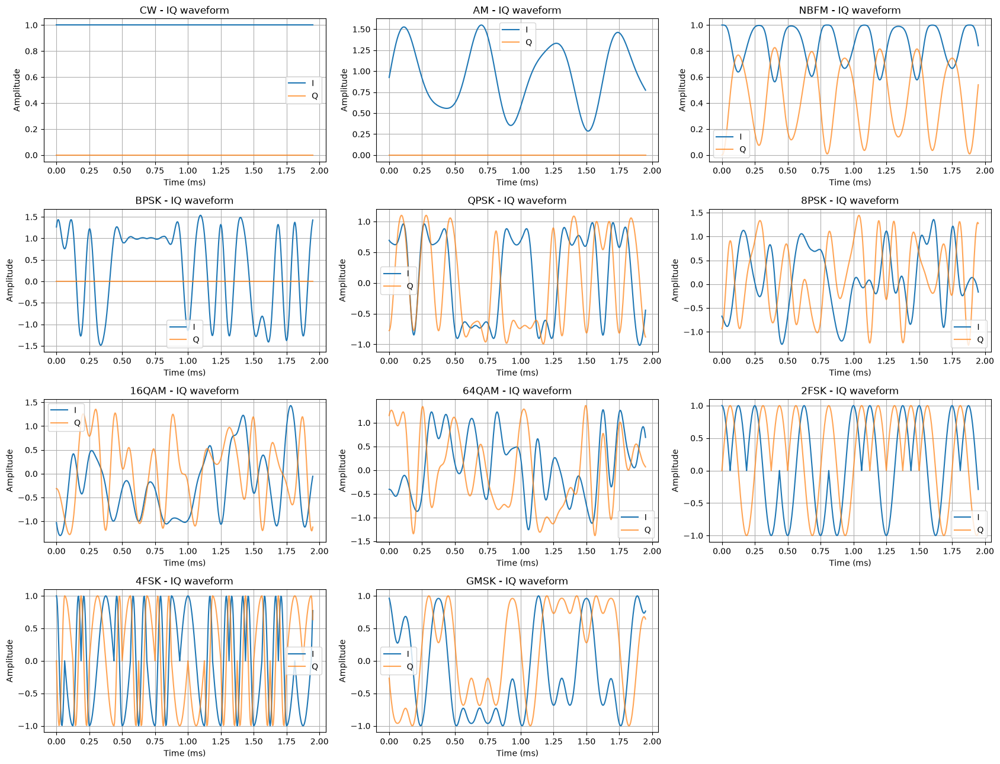

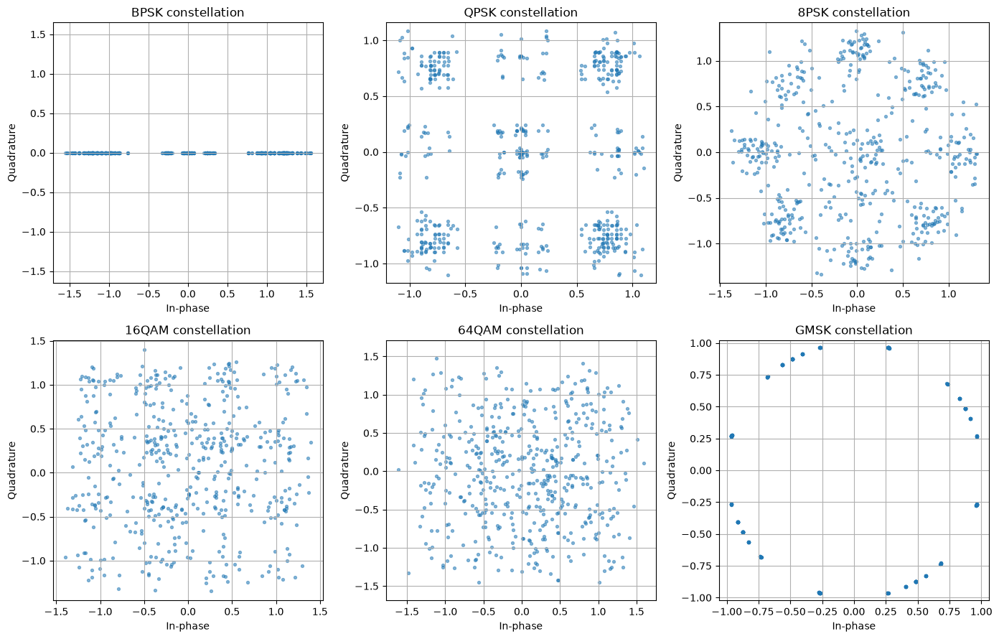

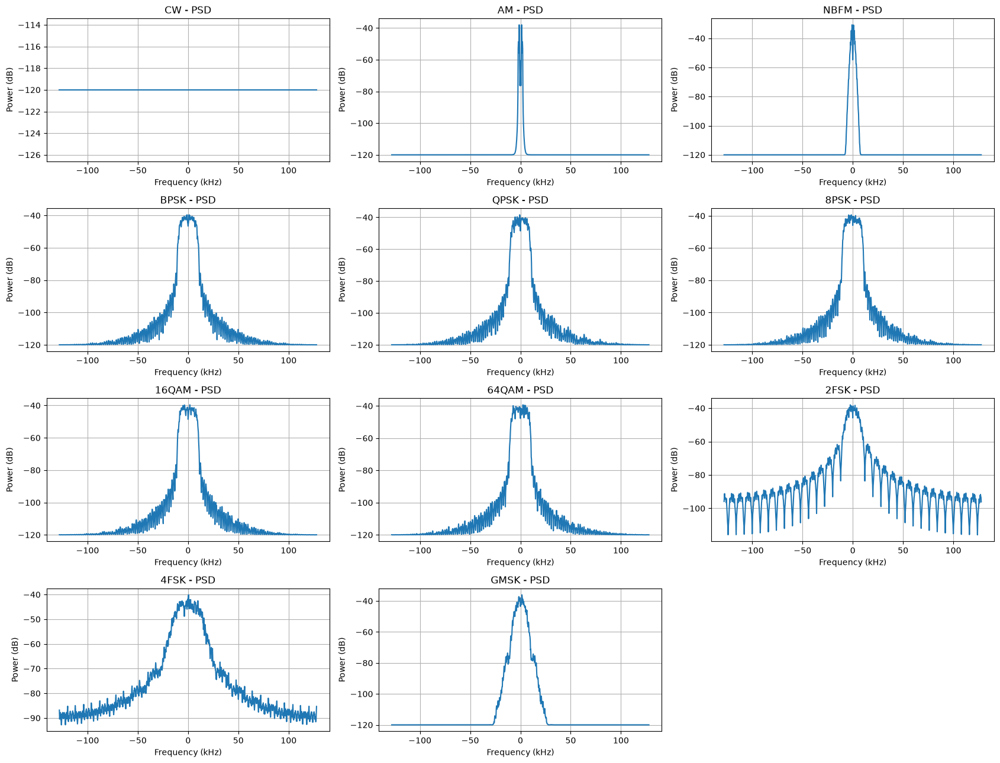

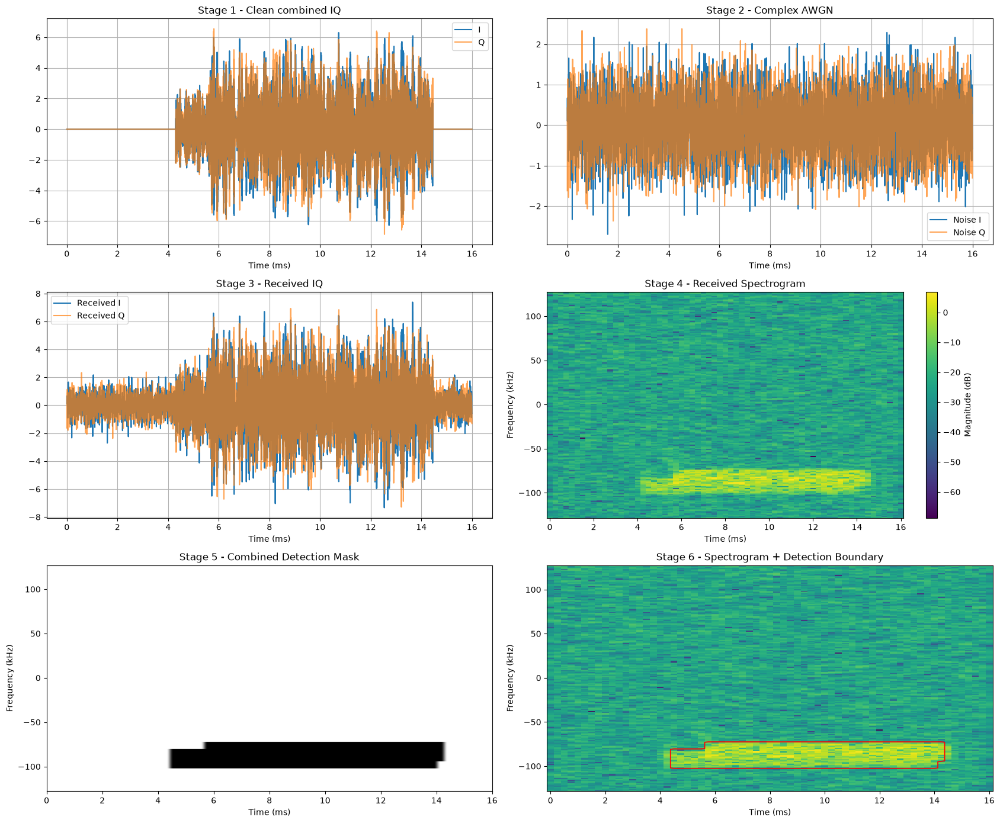


Emitter metadata:
Emitter 0 | 64QAM | Center: -91834.1 Hz | BW: 22000.0 Hz | SNR: 5.0 dB | Start: 1101 | End: 3609
Emitter 1 | 16QAM | Center: -83122.7 Hz | BW: 22000.0 Hz | SNR: 9.4 dB | Start: 1449 | End: 3700


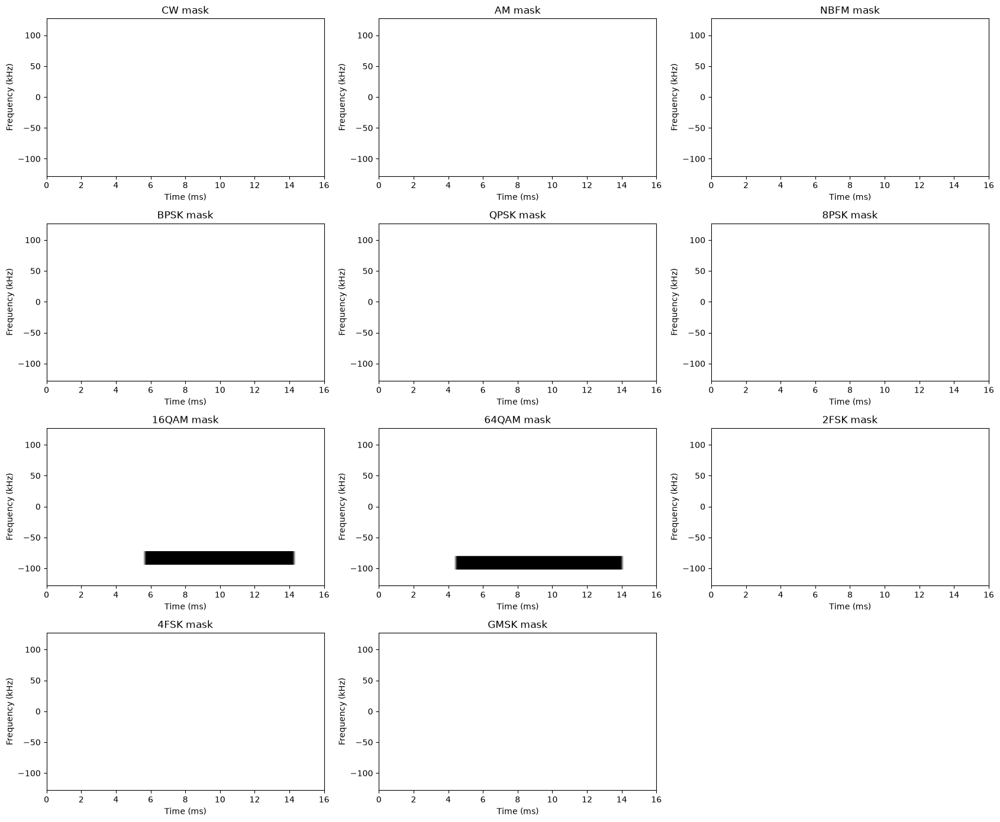


Tensor alignment checks:
IQ shape: (4096,)
STFT shape: (256, 65)
Spectrogram shape: (256, 65)
Mask shape: (11, 256, 65)
All tensor alignment checks passed.


In [9]:
# ============================================================
# Pre-generation quality control
# ============================================================

qc_rng = np.random.default_rng(1234)

# 1. Individual modulation waveforms.
plot_single_signal_examples(qc_rng)

# 2. Digital modulation constellation diagrams.
plot_constellation_examples(qc_rng)

# 3. Individual modulation PSD.
plot_psd_examples(qc_rng)

# 4. Generate and inspect a multi-emitter scene.
qc_scene = generate_scene(qc_rng)

plot_scene_stages(qc_scene)

# 5. Inspect class-specific masks.
plot_class_masks(qc_scene)

# 6. Check tensor alignment.
print("\nTensor alignment checks:")

print("IQ shape:", qc_scene["iq"].shape)
print("STFT shape:", qc_scene["stft"].shape)
print("Spectrogram shape:", qc_scene["spec_db"].shape)
print("Mask shape:", qc_scene["masks"].shape)

assert qc_scene["spec_db"].shape == (
    NFFT, NUM_FRAMES
)

assert qc_scene["masks"].shape == (
    NUM_CLASSES, NFFT, NUM_FRAMES
)

assert qc_scene["iq"].shape == (
    N_SAMPLES,
)

print("All tensor alignment checks passed.")

In [10]:
# ============================================================
# Dataset generation
# ============================================================

def generate_dataset_split(
    split_name,
    num_scenes,
    seed
):
    """Generate and save one independent dataset split."""

    rng = np.random.default_rng(seed)

    split_dir = os.path.join(
        OUTPUT_DIR,
        split_name
    )

    os.makedirs(split_dir, exist_ok=True)

    iq_data = np.zeros(
        (num_scenes, N_SAMPLES),
        dtype=np.complex64
    )

    spec_data = np.zeros(
        (num_scenes, NFFT, NUM_FRAMES),
        dtype=np.float16
    )

    mask_data = np.zeros(
        (
            num_scenes,
            NUM_CLASSES,
            NFFT,
            NUM_FRAMES
        ),
        dtype=np.uint8
    )

    scene_records = []
    signal_records = []

    for scene_id in tqdm(
        range(num_scenes),
        desc=f"Generating {split_name}"
    ):

        scene = generate_scene(rng)

        iq_data[scene_id] = scene["iq"]

        spec_data[scene_id] = (
            scene["spec_db"].astype(np.float16)
        )

        mask_data[scene_id] = scene["masks"]

        active_classes = sorted(
            set(
                e["class_name"]
                for e in scene["emitters"]
            )
        )

        scene_records.append({
            "scene_id": scene_id,
            "split": split_name,
            "num_emitters": len(scene["emitters"]),
            "active_classes": "|".join(active_classes),
            "mean_emitter_snr_db": np.mean([
                e["snr_db"]
                for e in scene["emitters"]
            ]),
            "min_emitter_snr_db": np.min([
                e["snr_db"]
                for e in scene["emitters"]
            ])
        })

        for emitter in scene["emitters"]:

            record = emitter.copy()

            record["scene_id"] = scene_id
            record["split"] = split_name

            signal_records.append(record)

    # Save numerical arrays.
    np.save(
        os.path.join(split_dir, "iq.npy"),
        iq_data
    )

    np.save(
        os.path.join(split_dir, "spec.npy"),
        spec_data
    )

    np.save(
        os.path.join(split_dir, "mask.npy"),
        mask_data
    )

    # Save metadata.
    pd.DataFrame(scene_records).to_csv(
        os.path.join(split_dir, "scenes.csv"),
        index=False
    )

    pd.DataFrame(signal_records).to_csv(
        os.path.join(split_dir, "signals.csv"),
        index=False
    )

    print(f"\nSaved {split_name}:")
    print("IQ:", iq_data.shape)
    print("Spectrogram:", spec_data.shape)
    print("Masks:", mask_data.shape)

    return (
        pd.DataFrame(scene_records),
        pd.DataFrame(signal_records)
    )


# ============================================================
# Generate all splits using independent seeds
# ============================================================

all_scenes = []
all_signals = []

split_seeds = {
    "train": RANDOM_SEED + 100,
    "val": RANDOM_SEED + 200,
    "test": RANDOM_SEED + 300
}

for split_name, num_scenes in SPLIT_SIZES.items():

    scenes_df, signals_df = generate_dataset_split(
        split_name=split_name,
        num_scenes=num_scenes,
        seed=split_seeds[split_name]
    )

    all_scenes.append(scenes_df)
    all_signals.append(signals_df)


all_scenes_df = pd.concat(
    all_scenes,
    ignore_index=True
)

all_signals_df = pd.concat(
    all_signals,
    ignore_index=True
)

all_scenes_df.to_csv(
    os.path.join(OUTPUT_DIR, "all_scenes.csv"),
    index=False
)

all_signals_df.to_csv(
    os.path.join(OUTPUT_DIR, "all_signals.csv"),
    index=False
)

print("\nDataset generation completed.")

Generating train: 100%|██████████| 1000/1000 [00:00<00:00, 1243.92it/s]



Saved train:
IQ: (1000, 4096)
Spectrogram: (1000, 256, 65)
Masks: (1000, 11, 256, 65)


Generating val: 100%|██████████| 200/200 [00:00<00:00, 1206.56it/s]



Saved val:
IQ: (200, 4096)
Spectrogram: (200, 256, 65)
Masks: (200, 11, 256, 65)


Generating test: 100%|██████████| 300/300 [00:00<00:00, 1236.19it/s]


Saved test:
IQ: (300, 4096)
Spectrogram: (300, 256, 65)
Masks: (300, 11, 256, 65)

Dataset generation completed.


In [11]:
# ============================================================
# Dataset quality statistics
# ============================================================

def dataset_quality_report(
    scenes_df,
    signals_df
):
    """Generate statistical quality reports."""

    print("\n========== DATASET QUALITY REPORT ==========\n")

    print("Total scenes:", len(scenes_df))
    print("Total emitters:", len(signals_df))

    print("\nScene count per split:")
    print(
        scenes_df["split"].value_counts()
    )

    print("\nEmitter count per scene:")
    print(
        scenes_df["num_emitters"].value_counts().sort_index()
    )

    print("\nClass distribution:")
    print(
        signals_df["class_name"].value_counts()
    )

    print("\nSNR statistics:")
    print(
        signals_df["snr_db"].describe()
    )

    floor_ratio = np.mean(
        np.isclose(
            signals_df["snr_db"],
            SNR_MIN_DB
        )
    )

    print(
        f"\nFraction of emitters at {SNR_MIN_DB} dB: "
        f"{floor_ratio:.3f}"
    )

    print("\nClass coverage by split:")

    coverage = pd.crosstab(
        signals_df["split"],
        signals_df["class_name"]
    )

    print(coverage)

    print("\nEmpty-mask check:")

    for split_name in SPLIT_SIZES:

        mask_path = os.path.join(
            OUTPUT_DIR,
            split_name,
            "mask.npy"
        )

        masks = np.load(
            mask_path,
            mmap_mode="r"
        )

        empty_scenes = np.sum(
            masks.sum(axis=(1, 2, 3)) == 0
        )

        print(
            split_name,
            "empty scenes:",
            int(empty_scenes)
        )

    return coverage


coverage = dataset_quality_report(
    all_scenes_df,
    all_signals_df
)


========== DATASET QUALITY REPORT ==========

Total scenes: 1500
Total emitters: 2962

Scene count per split:
split
train    1000
test      300
val       200
Name: count, dtype: int64

Emitter count per scene:
num_emitters
1    518
2    502
3    480
Name: count, dtype: int64

Class distribution:
class_name
CW       297
GMSK     296
2FSK     294
NBFM     284
8PSK     281
4FSK     261
16QAM    260
64QAM    257
AM       250
QPSK     242
BPSK     240
Name: count, dtype: int64

SNR statistics:
count    2962.000000
mean       10.583437
std         4.946896
min         5.000000
25%         5.000000
50%        10.045212
75%        14.908288
max        19.997603
Name: snr_db, dtype: float64

Fraction of emitters at 5.0 dB: 0.296

Class coverage by split:
class_name  16QAM  2FSK  4FSK  64QAM  8PSK   AM  BPSK   CW  GMSK  NBFM  QPSK
split                                                                       
test           40    61    62     52    54   47    58   50    56    70    46
train       

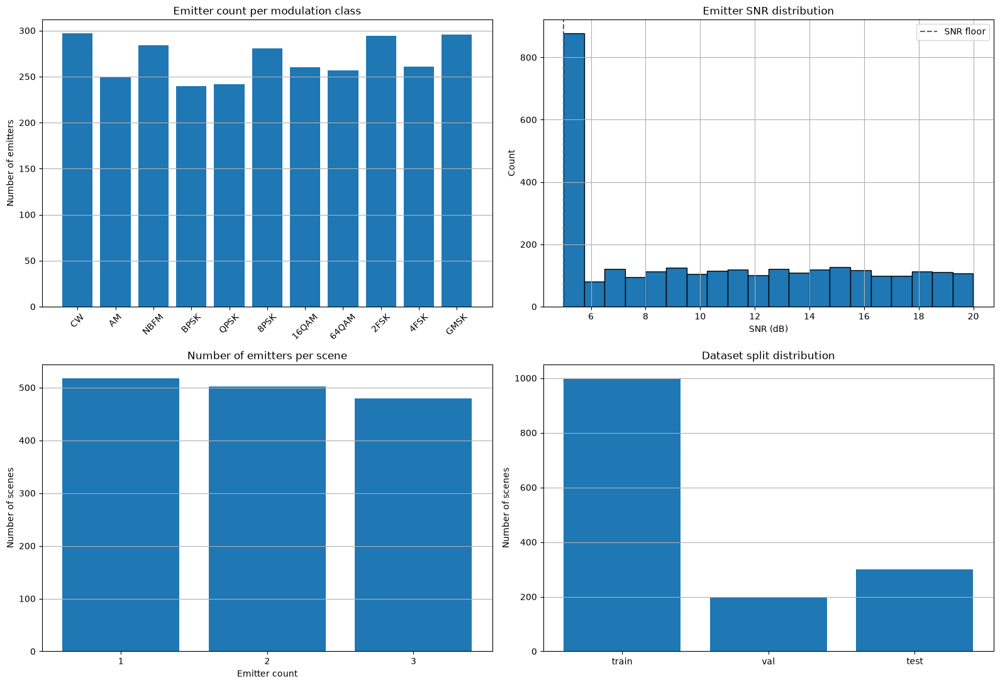

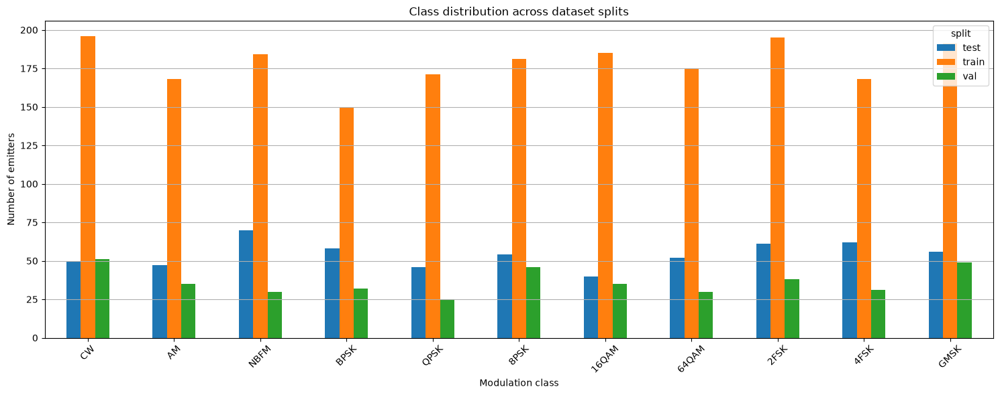

In [12]:
# ============================================================
# Dataset statistics visualization
# ============================================================

def plot_dataset_statistics(
    scenes_df,
    signals_df
):
    """Plot dataset-level quality statistics."""

    fig, axes = plt.subplots(
        2, 2,
        figsize=(16, 11)
    )

    # Class distribution.
    class_counts = (
        signals_df["class_name"]
        .value_counts()
        .reindex(CLASS_NAMES, fill_value=0)
    )

    axes[0, 0].bar(
        class_counts.index,
        class_counts.values
    )

    axes[0, 0].set_title(
        "Emitter count per modulation class"
    )

    axes[0, 0].set_ylabel("Number of emitters")
    axes[0, 0].tick_params(
        axis="x",
        rotation=45
    )
    axes[0, 0].grid(axis="y")

    # SNR distribution.
    axes[0, 1].hist(
        signals_df["snr_db"],
        bins=20,
        edgecolor="black"
    )

    axes[0, 1].axvline(
        SNR_MIN_DB,
        linestyle="--",
        label="SNR floor"
    )

    axes[0, 1].set_title(
        "Emitter SNR distribution"
    )

    axes[0, 1].set_xlabel("SNR (dB)")
    axes[0, 1].set_ylabel("Count")
    axes[0, 1].legend()
    axes[0, 1].grid(True)

    # Number of emitters per scene.
    emitter_counts = (
        scenes_df["num_emitters"]
        .value_counts()
        .sort_index()
    )

    axes[1, 0].bar(
        emitter_counts.index.astype(str),
        emitter_counts.values
    )

    axes[1, 0].set_title(
        "Number of emitters per scene"
    )

    axes[1, 0].set_xlabel("Emitter count")
    axes[1, 0].set_ylabel("Number of scenes")
    axes[1, 0].grid(axis="y")

    # Split sizes.
    split_counts = (
        scenes_df["split"]
        .value_counts()
        .reindex(["train", "val", "test"])
    )

    axes[1, 1].bar(
        split_counts.index,
        split_counts.values
    )

    axes[1, 1].set_title(
        "Dataset split distribution"
    )

    axes[1, 1].set_ylabel("Number of scenes")
    axes[1, 1].grid(axis="y")

    plt.tight_layout()
    plt.show()

    # Class distribution by split.
    split_class_counts = pd.crosstab(
        signals_df["class_name"],
        signals_df["split"]
    ).reindex(CLASS_NAMES)

    split_class_counts.plot(
        kind="bar",
        figsize=(15, 6)
    )

    plt.title(
        "Class distribution across dataset splits"
    )

    plt.ylabel("Number of emitters")
    plt.xlabel("Modulation class")
    plt.xticks(rotation=45)
    plt.grid(axis="y")
    plt.tight_layout()
    plt.show()


plot_dataset_statistics(
    all_scenes_df,
    all_signals_df
)

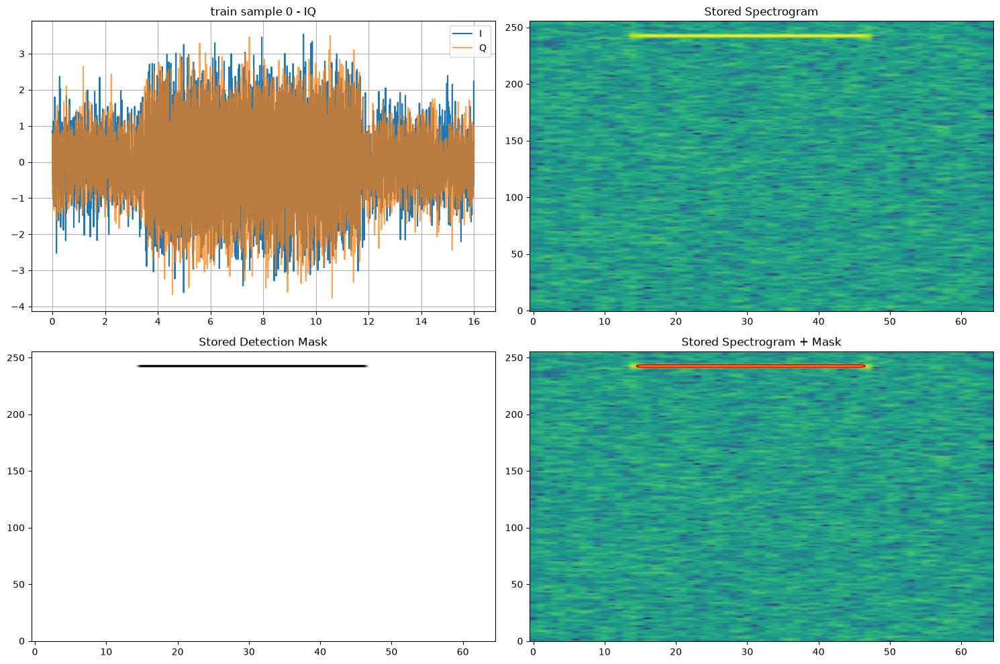

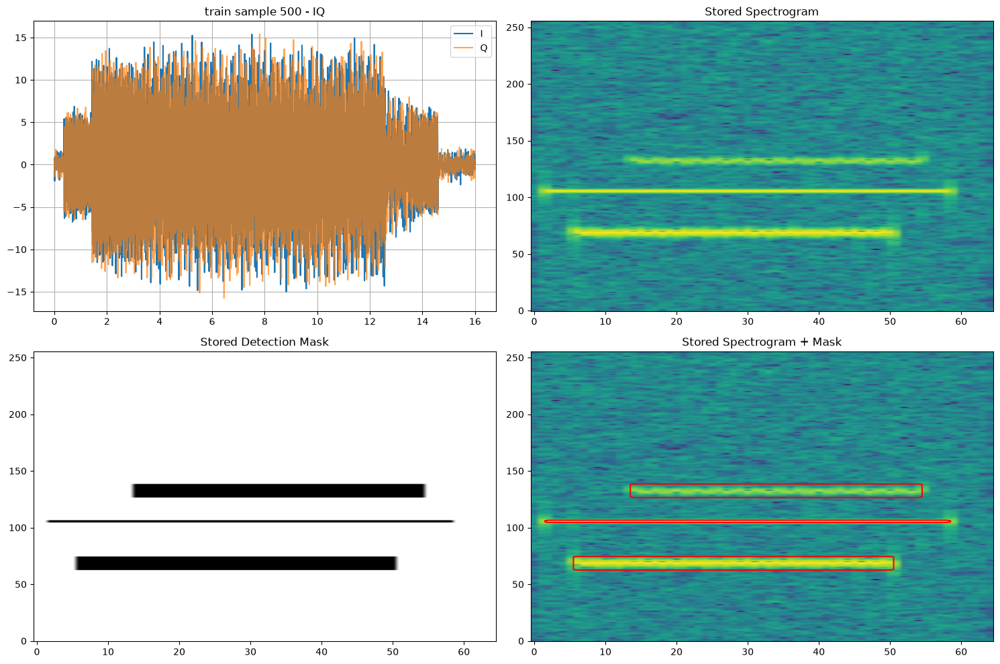

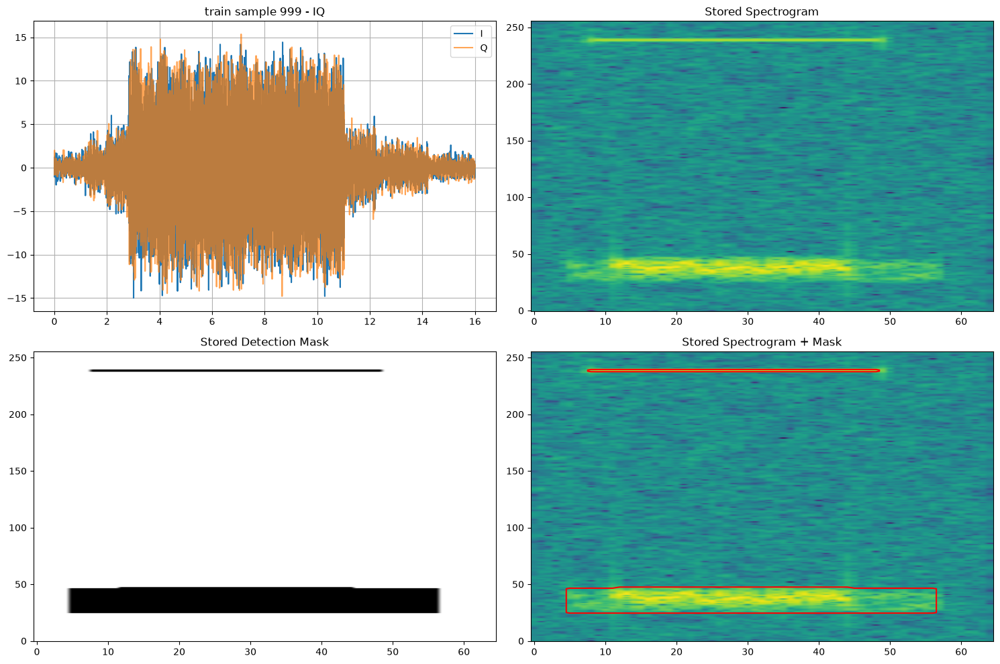

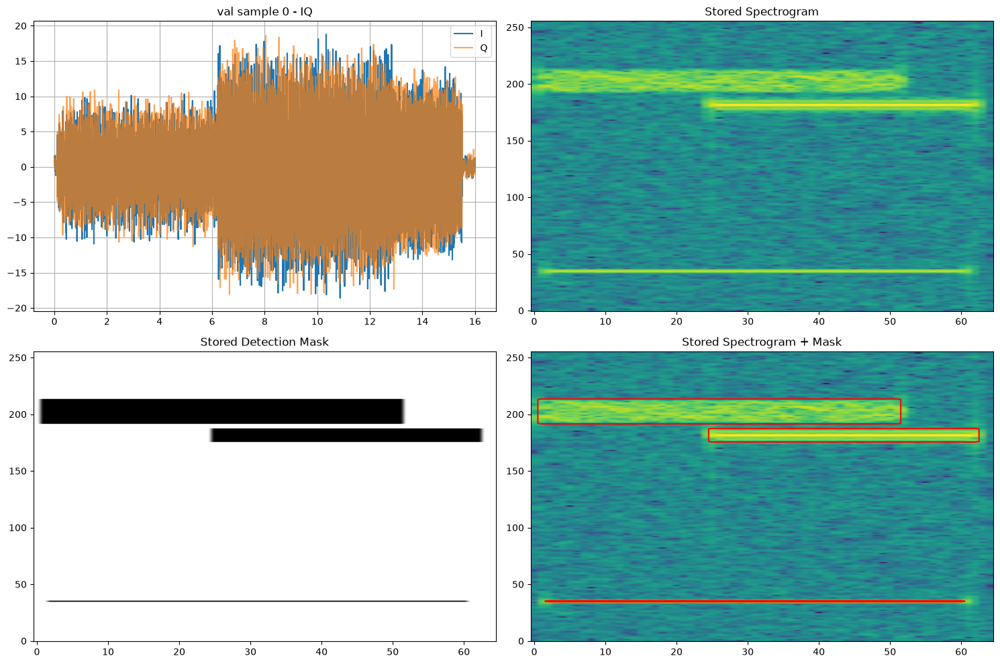

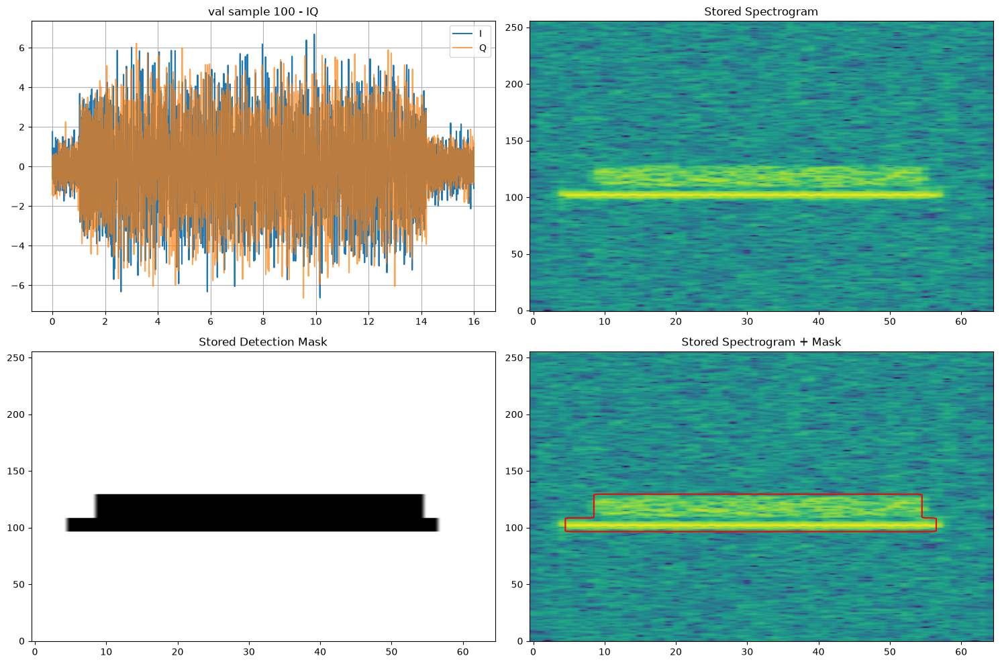

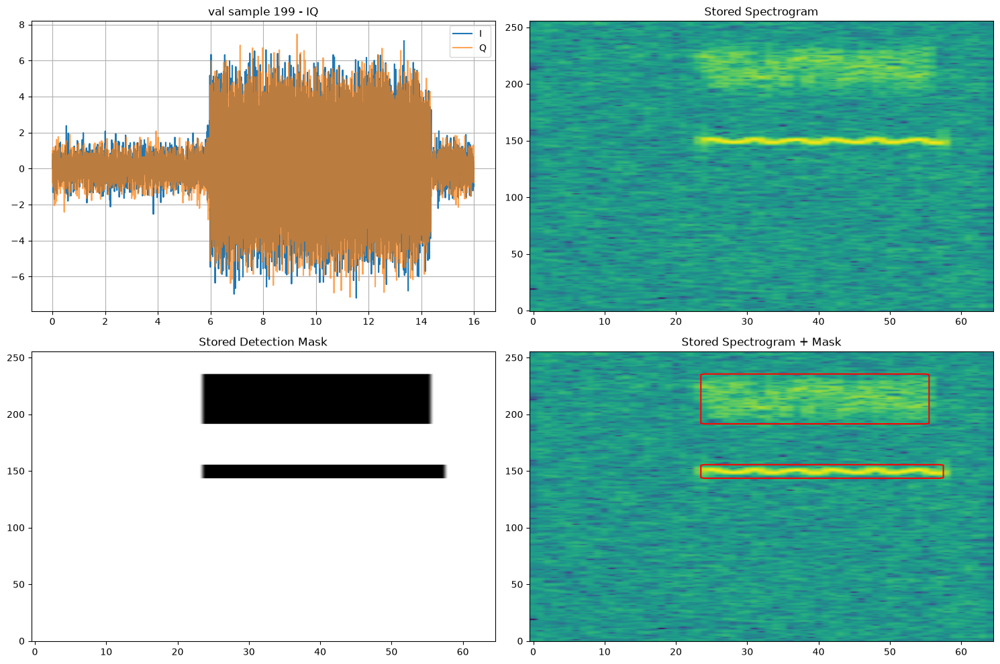

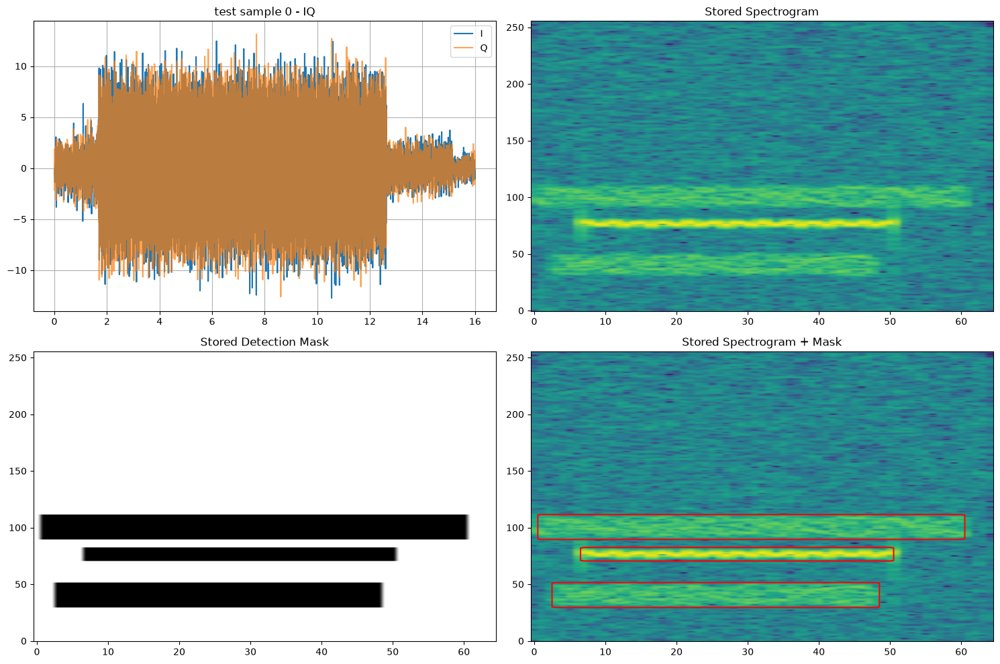

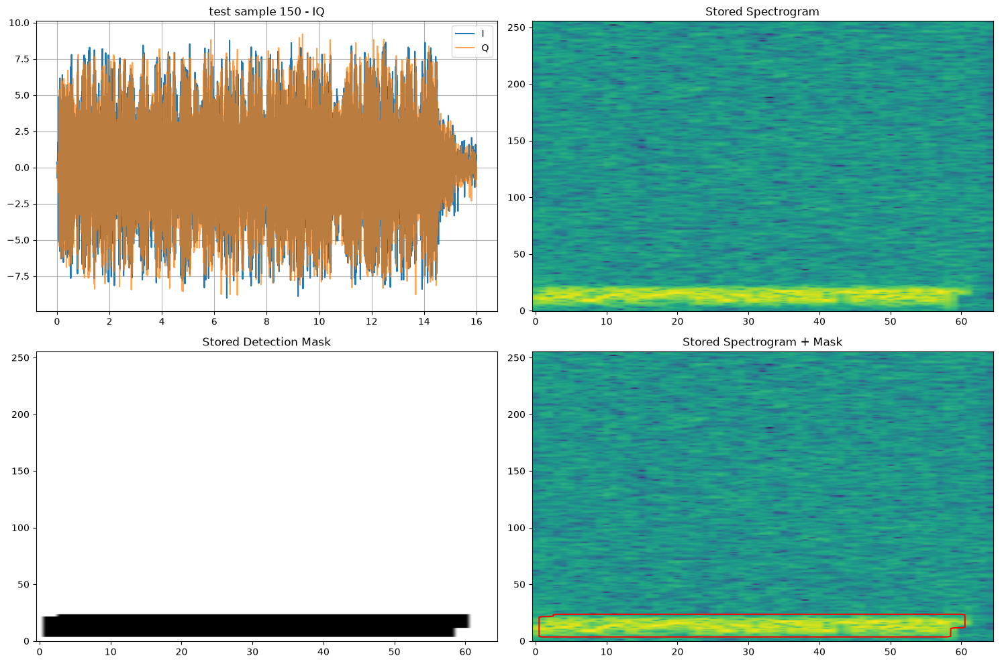

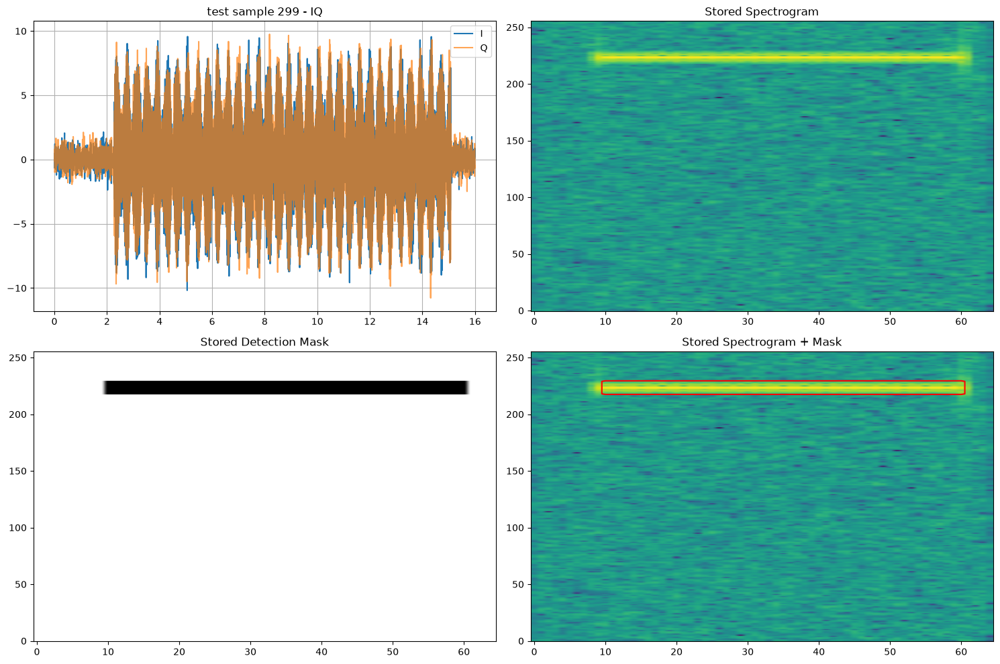

In [13]:
# ============================================================
# Inspect saved dataset samples
# ============================================================

def inspect_saved_samples(
    split_name="train",
    sample_indices=None
):
    """Load and plot selected samples from saved arrays."""

    split_dir = os.path.join(
        OUTPUT_DIR,
        split_name
    )

    iq_data = np.load(
        os.path.join(split_dir, "iq.npy"),
        mmap_mode="r"
    )

    spec_data = np.load(
        os.path.join(split_dir, "spec.npy"),
        mmap_mode="r"
    )

    mask_data = np.load(
        os.path.join(split_dir, "mask.npy"),
        mmap_mode="r"
    )

    if sample_indices is None:
        sample_indices = [
            0,
            len(iq_data) // 2,
            len(iq_data) - 1
        ]

    for sample_id in sample_indices:

        iq = iq_data[sample_id]
        spec = spec_data[sample_id]
        masks = mask_data[sample_id]

        fig, axes = plt.subplots(
            2, 2,
            figsize=(15, 10)
        )

        axes[0, 0].plot(
            TIME_AXIS * 1000,
            iq.real,
            label="I"
        )

        axes[0, 0].plot(
            TIME_AXIS * 1000,
            iq.imag,
            label="Q",
            alpha=0.7
        )

        axes[0, 0].set_title(
            f"{split_name} sample {sample_id} - IQ"
        )

        axes[0, 0].legend()
        axes[0, 0].grid(True)

        axes[0, 1].imshow(
            spec,
            origin="lower",
            aspect="auto",
            cmap="viridis"
        )

        axes[0, 1].set_title(
            "Stored Spectrogram"
        )

        combined_mask = np.max(
            masks,
            axis=0
        )

        axes[1, 0].imshow(
            combined_mask,
            origin="lower",
            aspect="auto",
            cmap="gray_r"
        )

        axes[1, 0].set_title(
            "Stored Detection Mask"
        )

        axes[1, 1].imshow(
            spec,
            origin="lower",
            aspect="auto",
            cmap="viridis"
        )

        axes[1, 1].contour(
            combined_mask,
            levels=[0.5],
            colors="red"
        )

        axes[1, 1].set_title(
            "Stored Spectrogram + Mask"
        )

        plt.tight_layout()
        plt.show()


inspect_saved_samples("train")
inspect_saved_samples("val")
inspect_saved_samples("test")

In [ ]:
# pip install ultralytics pillow scipy pyyaml

import os
import yaml
import numpy as np
import pandas as pd

from PIL import Image
from scipy.ndimage import zoom

# ============================================================
# YOLO dataset configuration
# ============================================================

SOURCE_DIR = "rf_mvp_dataset"
YOLO_DIR = "rf_yolo_dataset"

YOLO_IMAGE_HEIGHT = 1024
YOLO_IMAGE_WIDTH = 256

# Use a fixed dB range across all samples.
DB_MIN = -60.0
DB_MAX = 20.0

SPLITS = ["train", "val", "test"]

for split in SPLITS:
    os.makedirs(
        os.path.join(YOLO_DIR, "images", split),
        exist_ok=True
    )
    os.makedirs(
        os.path.join(YOLO_DIR, "labels", split),
        exist_ok=True
    )


def spectrogram_to_image(spec):
    """Convert a time-frequency matrix into a 3-channel image."""

    # Resize only the time axis.
    resized = zoom(
        spec,
        (
            YOLO_IMAGE_HEIGHT / spec.shape[0],
            YOLO_IMAGE_WIDTH / spec.shape[1]
        ),
        order=1
    )

    # Clip using a fixed dynamic range.
    resized = np.clip(
        resized,
        DB_MIN,
        DB_MAX
    )

    normalized = (
        (resized - DB_MIN)
        / (DB_MAX - DB_MIN)
    )

    image = (
        normalized * 255
    ).astype(np.uint8)

    # Repeat grayscale into three channels for YOLO.
    image_rgb = np.stack(
        [image, image, image],
        axis=-1
    )

    return image_rgb


def emitter_to_yolo_box(emitter):
    """Convert emitter metadata into normalized YOLO box coordinates."""

    # Time coordinates are normalized to the full recording duration.
    total_duration = N_SAMPLES / FS

    x1 = (
        emitter["start_sample"] / FS
    ) / total_duration

    x2 = (
        emitter["end_sample"] / FS
    ) / total_duration

    # Frequency coordinates follow the ascending frequency axis.
    f1 = (
        emitter["center_hz"]
        - emitter["bandwidth_hz"] / 2
    )

    f2 = (
        emitter["center_hz"]
        + emitter["bandwidth_hz"] / 2
    )

    y1 = (
        (f1 + FS / 2) / FS
    )

    y2 = (
        (f2 + FS / 2) / FS
    )

    # Clip coordinates to the valid image range.
    x1 = np.clip(x1, 0.0, 1.0)
    x2 = np.clip(x2, 0.0, 1.0)

    y1 = np.clip(y1, 0.0, 1.0)
    y2 = np.clip(y2, 0.0, 1.0)

    x_center = (x1 + x2) / 2
    y_center = (y1 + y2) / 2

    width = x2 - x1
    height = y2 - y1

    return (
        int(emitter["class_id"]),
        x_center,
        y_center,
        width,
        height
    )


# ============================================================
# Convert all splits
# ============================================================

for split in SPLITS:

    source_split = os.path.join(
        SOURCE_DIR, split
    )

    spec_data = np.load(
        os.path.join(source_split, "spec.npy"),
        mmap_mode="r"
    )

    signals_df = pd.read_csv(
        os.path.join(source_split, "signals.csv")
    )

    for scene_id in range(len(spec_data)):

        # Convert the stored spectrogram to an image.
        image_array = spectrogram_to_image(
            spec_data[scene_id].astype(np.float32)
        )

        image_name = f"{scene_id:06d}.png"

        image_path = os.path.join(
            YOLO_DIR,
            "images",
            split,
            image_name
        )

        Image.fromarray(
            image_array
        ).save(image_path)

        # Get all emitters belonging to this scene.
        scene_emitters = signals_df[
            signals_df["scene_id"] == scene_id
        ]

        label_lines = []

        for _, emitter in scene_emitters.iterrows():

            box = emitter_to_yolo_box(
                emitter
            )

            class_id, xc, yc, w, h = box

            if w <= 0 or h <= 0:
                continue

            label_lines.append(
                f"{class_id} "
                f"{xc:.8f} "
                f"{yc:.8f} "
                f"{w:.8f} "
                f"{h:.8f}"
            )

        label_path = os.path.join(
            YOLO_DIR,
            "labels",
            split,
            f"{scene_id:06d}.txt"
        )

        with open(
            label_path,
            "w",
            encoding="utf-8"
        ) as f:
            f.write(
                "\n".join(label_lines)
            )

    print(
        f"{split}: converted {len(spec_data)} scenes"
    )


# ============================================================
# Create YOLO dataset configuration
# ============================================================

dataset_yaml = {
    "path": os.path.abspath(YOLO_DIR),
    "train": "images/train",
    "val": "images/val",
    "test": "images/test",
    "names": {
        idx: name
        for idx, name in enumerate(CLASS_NAMES)
    }
}

yaml_path = os.path.join(
    YOLO_DIR,
    "rf_dataset.yaml"
)

with open(
    yaml_path,
    "w",
    encoding="utf-8"
) as f:
    yaml.safe_dump(
        dataset_yaml,
        f,
        sort_keys=False,
        allow_unicode=True
    )

print("\nYOLO dataset preparation completed.")
print("Dataset YAML:", yaml_path)

In [ ]:
# ============================================================
# Visualize YOLO labels
# ============================================================

import matplotlib.pyplot as plt
import matplotlib.patches as patches

def inspect_yolo_sample(
    split="train",
    sample_id=0
):
    image_path = os.path.join(
        YOLO_DIR,
        "images",
        split,
        f"{sample_id:06d}.png"
    )

    label_path = os.path.join(
        YOLO_DIR,
        "labels",
        split,
        f"{sample_id:06d}.txt"
    )

    image = np.asarray(
        Image.open(image_path)
    )

    fig, ax = plt.subplots(
        figsize=(14, 7)
    )

    ax.imshow(image)

    if os.path.exists(label_path):

        with open(
            label_path,
            "r",
            encoding="utf-8"
        ) as f:

            for line in f:

                values = line.strip().split()

                if len(values) != 5:
                    continue

                class_id = int(values[0])

                xc, yc, w, h = map(
                    float,
                    values[1:]
                )

                x1 = (
                    xc - w / 2
                ) * image.shape[1]

                y1 = (
                    yc - h / 2
                ) * image.shape[0]

                box_w = w * image.shape[1]
                box_h = h * image.shape[0]

                rect = patches.Rectangle(
                    (x1, y1),
                    box_w,
                    box_h,
                    linewidth=2,
                    edgecolor="red",
                    facecolor="none"
                )

                ax.add_patch(rect)

                ax.text(
                    x1,
                    y1,
                    CLASS_NAMES[class_id],
                    color="white",
                    fontsize=9,
                    bbox={"facecolor": "red", "alpha": 0.7}
                )

    ax.set_title(
        f"YOLO label inspection: {split}/{sample_id}"
    )

    ax.set_xlabel("Time")
    ax.set_ylabel("Frequency-bin image coordinate")

    plt.tight_layout()
    plt.show()


inspect_yolo_sample("train", 0)
inspect_yolo_sample("train", 1)
inspect_yolo_sample("val", 0)

In [ ]:
!pip install -U ultralytics

In [ ]:
# pip install -U ultralytics

from ultralytics import YOLO
import torch
import ultralytics

print("Ultralytics:", ultralytics.__version__)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


# ============================================================
# YOLO26n baseline training
# ============================================================

DATA_YAML = os.path.abspath(
    os.path.join(YOLO_DIR, "rf_dataset.yaml")
)

model = YOLO("yolo26n.pt")

train_results = model.train(
    data=DATA_YAML,

    epochs=100,
    imgsz=640,
    batch=16,

    optimizer="auto",
    patience=20,

    project="rf_yolo_runs",
    name="yolo26n_pretrained_baseline",

    pretrained=True,

    # Preserve time-frequency semantics.
    fliplr=0.0,
    flipud=0.0,
    degrees=0.0,
    shear=0.0,
    perspective=0.0,

    # Disable aggressive image mixing.
    mosaic=0.0,
    mixup=0.0,
    copy_paste=0.0,

    # Conservative scaling.
    scale=0.05,
    translate=0.0,

    # Reproducibility.
    seed=42,
    deterministic=True,

    # Runtime.
    workers=4,
    device=0 if torch.cuda.is_available() else "cpu",

    plots=True,
    save=True,
    verbose=True
)

In [ ]:
from ultralytics import YOLO
import os
import pandas as pd

# Load best checkpoint
model = YOLO(
    "/content/runs/detect/rf_yolo_runs/yolo26n_pretrained_baseline-2/weights/best.pt"
)

# Run evaluation on untouched test set
metrics = model.val(
    data="/content/rf_yolo_dataset/rf_dataset.yaml",
    split="test",
    imgsz=640,
    batch=16,
    conf=0.001,
    iou=0.6,
    plots=True,
    save_json=True,
    project="/content/runs/detect/rf_yolo_runs",
    name="yolo26n_final_test",
)

# Save metrics
output_dir = "/content/runs/detect/rf_yolo_runs/yolo26n_final_test"
os.makedirs(output_dir, exist_ok=True)

overall = {
    "Precision": float(metrics.box.mp),
    "Recall": float(metrics.box.mr),
    "mAP50": float(metrics.box.map50),
    "mAP50-95": float(metrics.box.map),
}

print("\n========== OVERALL TEST RESULTS ==========")
print(pd.DataFrame([overall]).to_string(index=False))

# Per-class evaluation
class_results = []

for i, name in model.names.items():
    class_results.append({
        "Class": name,
        "Precision": float(metrics.box.p[i]),
        "Recall": float(metrics.box.r[i]),
        "mAP50": float(metrics.box.ap50[i]),
        "mAP50-95": float(metrics.box.ap[i]),
    })

df = pd.DataFrame(class_results)

print("\n========== PER CLASS RESULTS ==========")
print(df.to_string(index=False))

df.to_csv(
    f"{output_dir}/per_class_metrics.csv",
    index=False
)

pd.DataFrame([overall]).to_csv(
    f"{output_dir}/overall_metrics.csv",
    index=False
)

print("\nAll metrics saved successfully.")
print("Output directory:", output_dir)

In [ ]:

from ultralytics import YOLO
import os
import pandas as pd

# Load best checkpoint
model = YOLO(
    "/content/runs/detect/rf_yolo_runs/yolo26n_pretrained_baseline-2/weights/best.pt"
)

# Run evaluation on untouched test set
metrics = model.val(
    data="/content/rf_yolo_dataset/rf_dataset.yaml",
    split="test",
    imgsz=640,
    batch=16,
    conf=0.001,
    iou=0.6,
    plots=True,
    save_json=True,
    project="/content/runs/detect/rf_yolo_runs",
    name="yolo26n_final_test",
)

# Save metrics
output_dir = "/content/runs/detect/rf_yolo_runs/yolo26n_final_test"
os.makedirs(output_dir, exist_ok=True)

overall = {
    "Precision": float(metrics.box.mp),
    "Recall": float(metrics.box.mr),
    "mAP50": float(metrics.box.map50),
    "mAP50-95": float(metrics.box.map),
}

print("\n========== OVERALL TEST RESULTS ==========")
print(pd.DataFrame([overall]).to_string(index=False))

# Per-class evaluation
class_results = []

for i, name in model.names.items():
    class_results.append({
        "Class": name,
        "Precision": float(metrics.box.p[i]),
        "Recall": float(metrics.box.r[i]),
        "mAP50": float(metrics.box.ap50[i]),
        "mAP50-95": float(metrics.box.ap[i]),
    })

df = pd.DataFrame(class_results)

print("\n========== PER CLASS RESULTS ==========")
print(df.to_string(index=False))

df.to_csv(
    f"{output_dir}/per_class_metrics.csv",
    index=False
)

pd.DataFrame([overall]).to_csv(
    f"{output_dir}/overall_metrics.csv",
    index=False
)

print("\nAll metrics saved successfully.")
print("Output directory:", output_dir)

In [ ]:
from ultralytics import YOLO
import os
import pandas as pd

# Load best checkpoint
model = YOLO(
    "/content/runs/detect/rf_yolo_runs/yolo26n_pretrained_baseline-2/weights/best.pt"
)

# Run evaluation on untouched test set
metrics = model.val(
    data="/content/rf_yolo_dataset/rf_dataset.yaml",
    split="test",
    imgsz=640,
    batch=16,
    conf=0.001,
    iou=0.6,
    plots=True,
    save_json=True,
    project="/content/runs/detect/rf_yolo_runs",
    name="yolo26n_final_test",
)

# Save metrics
output_dir = "/content/runs/detect/rf_yolo_runs/yolo26n_final_test"
os.makedirs(output_dir, exist_ok=True)

overall = {
    "Precision": float(metrics.box.mp),
    "Recall": float(metrics.box.mr),
    "mAP50": float(metrics.box.map50),
    "mAP50-95": float(metrics.box.map),
}

print("\n========== OVERALL TEST RESULTS ==========")
print(pd.DataFrame([overall]).to_string(index=False))

# Per-class evaluation
class_results = []

for i, name in model.names.items():
    class_results.append({
        "Class": name,
        "Precision": float(metrics.box.p[i]),
        "Recall": float(metrics.box.r[i]),
        "mAP50": float(metrics.box.ap50[i]),
        "mAP50-95": float(metrics.box.ap[i]),
    })

df = pd.DataFrame(class_results)

print("\n========== PER CLASS RESULTS ==========")
print(df.to_string(index=False))

df.to_csv(
    f"{output_dir}/per_class_metrics.csv",
    index=False
)

pd.DataFrame([overall]).to_csv(
    f"{output_dir}/overall_metrics.csv",
    index=False
)

print("\nAll metrics saved successfully.")
print("Output directory:", output_dir)

In [ ]:
# ============================================================
# Evaluate YOLO26n on the held-out test split
# =============================================================

BEST_MODEL_PATH = os.path.join(
    "runs",
    "detect",
    "rf_yolo_runs",
    "yolo26n_pretrained_baseline",
    "weights",
    "best.pt"
)

best_model = YOLO(BEST_MODEL_PATH)

test_metrics = best_model.val(
    data=DATA_YAML,
    split="test",
    imgsz=640,
    batch=16,
    plots=True,
    project="rf_yolo_runs",
    name="yolo26n_test"
)

print("\nYOLO26n Test Results")

print("mAP50:", test_metrics.box.map50)
print("mAP50-95:", test_metrics.box.map)
print("Per-class mAP50-95:", test_metrics.box.maps)

In [ ]:
from ultralytics import YOLO

model = YOLO("/content/runs/detect/rf_yolo_runs/yolo26n/weights/last.pt")

model.train(
    resume=True,
)

In [ ]:
from ultralytics import YOLO

model = YOLO("/content/runs/detect/rf_yolo_runs/yolo26n/weights/best.pt")

model.train(
    data="/content/rf_yolo_dataset/data.yaml",
    epochs=100,
    imgsz=640,
    batch=16,
    patience=20,
    optimizer="AdamW",
    lr0=0.001,
    weight_decay=0.0005,
    cos_lr=True,
    project="/content/runs/detect/rf_yolo_runs",
    name="yolo26n_100ep",
    exist_ok=True,
    plots=True,
    save=True,
    seed=42
)

In [ ]:


from ultralytics import YOLO
import os
import pandas as pd

# Best trained model
model = YOLO(
    "/content/runs/detect/rf_yolo_runs/yolo26n_100ep/weights/best.pt"
)

# Test evaluation
metrics = model.val(
    data="/content/rf_yolo_dataset/data.yaml",
    split="test",
    imgsz=640,
    batch=16,
    conf=0.001,
    iou=0.6,
    plots=True,
    save_json=True,
    project="/content/runs/detect/rf_yolo_runs",
    name="yolo26n_100ep_test"
)

# Output directory
output_dir = "/content/runs/detect/rf_yolo_runs/yolo26n_100ep_test"

os.makedirs(output_dir, exist_ok=True)

# Overall metrics
results = {
    "Precision": metrics.box.mp,
    "Recall": metrics.box.mr,
    "mAP50": metrics.box.map50,
    "mAP50-95": metrics.box.map,
}

print("\n========== Overall Test Results ==========")

for key, value in results.items():
    print(f"{key}: {value:.4f}")

# Per-class metrics
class_results = []

for i, class_name in model.names.items():

    class_results.append({
        "Class": class_name,
        "Precision": float(metrics.box.p[i]),
        "Recall": float(metrics.box.r[i]),
        "mAP50": float(metrics.box.ap50[i]),
        "mAP50-95": float(metrics.box.ap[i]),
    })

df = pd.DataFrame(class_results)

print("\n========== Per-Class Test Results ==========")
print(df.to_string(index=False))

# Save results
df.to_csv(
    f"{output_dir}/per_class_metrics.csv",
    index=False
)

pd.DataFrame([results]).to_csv(
    f"{output_dir}/overall_metrics.csv",
    index=False
)

print("\nResults saved successfully.")

# downoad data set

In [ ]:
import shutil

# Compress the dataset directory into a ZIP archive
shutil.make_archive(
    '/content/rf_yolo_dataset',
    'zip',
    '/content',
    'rf_yolo_dataset'
)

print("Dataset compressed successfully: /content/rf_yolo_dataset.zip")

In [ ]:
from google.colab import files

files.download('/content/rf_yolo_dataset.zip')